# [이론] LLM 라벨 검증 — 골드 표본과 비율 보정

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## 0. 왜 LLM 라벨을 검증하는가

<div style="background:#FFFFFF;color:#000000;padding:40px;border-radius:12px;border:1px solid #E6E6E6;border-left:4px solid #051C2C">
<div style="font-size:0.9em;color:#656565">AI 데이터 인텔리전스 전문가 과정 · 비정형 데이터(자연어)</div>
<h1 style="color:#000000;margin:10px 0">LLM 라벨 검증 — 골드 표본과 비율 보정</h1>
<div style="font-size:1.05em;color:#656565">LLM 라벨로 계산한 불만 비율을 그대로 써도 되는지 골드 표본과 별점으로 확인하고 참값이 있는 표본으로 비율을 보정합니다</div>
</div>

본문은 필수이고, 접힌 상자(「자세히」·「더 깊이」)는 선택입니다.

### 핵심 질문: LLM 라벨로 계산한 비율을 그대로 써도 되는가 [필수]

LLM 라벨링 때 본 텀블러 리뷰 10건의 쇼핑몰에서 리뷰 500건을 무작위로 모았다고 가정한 가상의 예입니다.

LLM 은 리뷰마다 「불만 있음 · 없음」 라벨을 냈습니다. 근거가 확인된 부정 속성 라벨이 하나라도 있는 리뷰가 「있음」입니다. **불만 비율** 은 「있음」 리뷰의 비율입니다.

```text
텀블러 리뷰 500건 → LLM 「있음」 160건 → LLM 라벨로 구한 불만 비율 160 ÷ 500 = 0.32
```

> LLM 라벨로 구한 불만 비율 0.32 를 그대로 써도 되는가?

그대로 쓰지 않습니다. LLM 이 한쪽으로 더 자주 틀리면 비율도 그만큼 어긋나기 때문입니다.

- 골드 표본은 사람이 직접 라벨링한 무작위 리뷰입니다. 비율은 골드 표본으로 LLM 이 어긋난 만큼 고쳐 씁니다(「3. 예측 기반 추론(PPI)」).
- 고친 비율도 골드 표본 건수로 구한 95% 구간만큼 불확실합니다. 골드 표본이 작으면 구간이 넓습니다.
- 두 집단을 비교할 때는 LLM 이 두 집단에서 같은 방향 · 같은 크기로 틀리는지 먼저 확인합니다(「4. 집단마다 다른 라벨 오차」).

**일치율이 높으면 비율도 맞나요?**

500건에서 무작위로 20건을 골라, 사람이 LLM 라벨을 보지 않고 라벨링했습니다.

**참값** 은 그 리뷰의 맞는 라벨로 믿고 쓰는 값입니다. 사람이 원문을 읽고 정한 라벨이나 고객이 고른 별점을 참값으로 씁니다. 참값도 틀릴 수 있습니다. 사람도 잘못 읽고, 고객도 별점을 잘못 누릅니다(LLM 라벨링 때의 예시 리뷰 7 「좋아요」에 별점 1점).

여기서는 사람 라벨을 참값으로 씁니다.

| | 사람 있음 | 사람 없음 | 합 |
|---|---:|---:|---:|
| LLM 있음 | 5 | 2 | 7 |
| LLM 없음 | 1 | 12 | 13 |
| 합 | 6 | 14 | 20 |

**일치율** 은 두 라벨이 같은 리뷰의 비율입니다. 같은 리뷰는 5 + 12 = 17건이라 일치율은 0.85 입니다. LLM 라벨링 때 별점과 비교한 일치율도 극성이 같은 리뷰 수를 전체 리뷰 수로 나눠 구했습니다.

그런데 불만 비율은 두 라벨에서 다릅니다.

```text
골드 표본 20건, 사람 라벨의 불만 비율: 6 ÷ 20 = 0.30
골드 표본 20건, LLM 라벨의 불만 비율: 7 ÷ 20 = 0.35 → LLM 쪽이 0.05 높음
```

두 값은 같은 골드 표본 20건에서 구한 비율입니다. 앞의 0.32 는 500건 전체의 LLM 라벨로 구한 값입니다.

일치율은 리뷰 한 건씩 맞았는지를 따진 수입니다. 비율이 맞는지는 두 라벨이 다른 리뷰 가운데 어느 방향(LLM 만 「있음」 · 사람만 「있음」)이 더 많은지에 달려 있습니다.

| 두 라벨이 다른 리뷰 | 건수 | 리뷰 |
|---|---:|---|
| LLM 만 있음 | 2 | 「뚜껑이 좀 뻑뻑하지만 오히려 안 새서 좋아요」, 「생각보다 무겁긴 한데 튼튼해서 만족합니다」 |
| 사람만 있음 | 1 | 「두 번째 구매인데 이번엔 색이 좀 다르네요」 |

LLM 「있음」 7건과 사람 「있음」 6건은 모두 둘 다 「있음」인 5건을 포함합니다.

```text
LLM 「있음」 7건 = 둘 다 있음 5건 + LLM 만 있음 2건
사람 「있음」 6건 = 둘 다 있음 5건 + 사람만 있음 1건
7 − 6 = (5 + 2) − (5 + 1) = 2 − 1 = 1건
1 ÷ 20 = 0.05 = 0.35 − 0.30
```

이 5건은 양쪽에 똑같이 있어 차이를 만들지 않습니다. 두 비율의 차이는 두 라벨이 다른 리뷰의 두 방향(LLM 만 있음 · 사람만 있음) 건수 차이에서만 생깁니다.

그래서 일치율이 같아도 비율 차이는 달라질 수 있습니다. 두 라벨이 다른 3건이 모두 LLM 만 있음이었다면 일치율은 그대로 0.85 이지만 차이는 0.15 입니다. 두 방향의 건수가 같으면, 예를 들어 2건씩이면 차이는 0 입니다.

**편향(bias)** 은 LLM 라벨 비율이 참값 비율에서 한쪽으로 어긋난 크기입니다. 골드 표본 20건에서는 LLM 쪽이 0.05 높은 편향이 보입니다.

**LLM 이 라벨링하는 리뷰를 늘리면 편향이 줄어드나요?**

줄지 않습니다. LLM 이 라벨링하는 리뷰를 500건에서 5,000건으로 늘려도, 0.32 가 표본마다 덜 달라질 뿐입니다. 한쪽으로 틀리는 만큼은 그대로 남습니다. LLM 라벨 비율의 오차는 두 가지로 나뉩니다.

- 표본마다 달라지는 오차: 다른 500건을 LLM 으로 라벨링하면 0.32 도 조금 커지거나 작아집니다. 라벨링하는 리뷰를 늘리면 이 오차는 줄어듭니다.
- 편향: LLM 이 「있음」 쪽으로 더 자주 틀리면, 몇 건을 라벨링해도 0.32 는 같은 쪽으로 어긋납니다.

<img src="https://upload.wikimedia.org/wikipedia/commons/5/5d/Reliability_and_validity.svg" alt="과녁 네 개. 왼쪽 위는 점이 넓게 퍼지고 가운데에서 비켜남, 오른쪽 위는 넓게 퍼졌지만 가운데를 에워쌈, 왼쪽 아래는 좁게 뭉쳤지만 가운데에서 비켜남, 오른쪽 아래는 가운데에 좁게 뭉침" width="520" height="557" />
<p align="center"><em>▲ 과녁 네 개에서 점 하나는 표본 한 번으로 구한 값이고, 과녁 가운데는 참값 비율이다. 점이 좁게 모일수록 표본마다 값이 덜 달라진다. 가운데에서 떨어진 거리가 편향이다. 왼쪽 아래(Reliable, Not Valid)는 값이 일정하지만 가운데를 맞히지 못한 경우다 (출처: Wikimedia Commons, Reliability and validity.svg, Nevit Dilmen, CC BY-SA 3.0)</em></p>

과녁 가운데는 참값 비율입니다. 이 쇼핑몰의 텀블러 리뷰를 모두 사람이 라벨링했다면 나올 불만 비율이고, 리뷰 500건은 그 가운데 무작위로 고른 표본입니다. LLM 이 「있음」 쪽으로 더 자주 틀리면, LLM 라벨 비율 0.32 는 왼쪽 아래 과녁과 같습니다.

점은 좁게 모이지만, 모인 곳은 가운데에서 편향만큼 비켜나 있습니다.

> LLM 이 라벨링하는 리뷰를 늘리면 점이 더 좁게 모일 뿐, 편향은 그대로 남습니다.

리뷰 2만 건에 같은 확인을 한 결과는 「5. 리뷰 2만 건 검증과 팀 라운드」에 모았습니다.

<div class="lms-summary">

**정리**

LLM 라벨로 구한 불만 비율은 그대로 쓰지 않습니다. 일치율이 높아도 두 라벨이 다른 리뷰가 한쪽 방향으로 더 많으면 비율에 편향이 생깁니다.

**할 일**

- 불만 비율은 골드 표본으로 고친 비율을 쓰고, 값 하나가 아니라 골드 표본 건수로 구한 95% 구간으로 씁니다
- 두 집단을 비교할 때는 LLM 라벨의 편향이 두 집단에서 같은지 먼저 확인합니다(「4. 집단마다 다른 라벨 오차」)

편향은 LLM 이 라벨링하는 리뷰를 늘려도 줄지 않습니다.

</div>

## 1. 골드 표본

불만 있음 라벨이 맞는지 보려면 사람이 리뷰를 몇 건, 어떻게 라벨링해야 할까요? 무작위로 고른 리뷰를 LLM 라벨을 보지 않고 라벨링합니다. 건수가 많을수록 일치율의 범위가 좁아지지만, 범위를 절반으로 줄이려면 건수가 네 배 필요합니다.

### 골드 표본은 몇 건이 필요한가 [필수]

**골드 표본(gold standard)** 은 무작위로 고른 리뷰를 사람이 직접 라벨링해 참값으로 삼는 표본입니다. gold standard 는 다른 값을 비교할 때 기준으로 삼는 값이라는 뜻입니다. 골드 스탠다드 · 정답 데이터라고도 부릅니다. 골드 스탠다드 · 정답 데이터라고도 부릅니다. 텀블러 리뷰 500건에서 고른 20건이 골드 표본입니다.

**골드 표본은 언제 만드나요?**

LLM 라벨과 비교할 참값이 리뷰에 따로 없을 때 만듭니다.

| LLM 라벨 | 비교할 참값 |
|---|---|
| 리뷰 전체 극성(긍정 · 부정) | 고객이 고른 별점. 리뷰마다 있음 |
| 불만 있음 · 속성 라벨 | 따로 없음 → 골드 표본을 만듦 |

별점은 리뷰 한 건에 매긴 수 하나라, 별점만으로는 속성마다 불만이 있는지 알 수 없습니다. LLM 라벨링 때의 예시 리뷰 5 「가격은 괜찮은데 손잡이가 약해요」는 별점이 4점이지만 품질 불만이 있습니다.

**다른 20건을 골랐다면 일치율은 어디까지 달라지나요?**

골드 표본의 일치율 0.85 는 어느 20건을 골랐느냐에 따라 조금 크거나 작게 나옵니다. 500건을 모두 사람이 라벨링했을 때의 일치율과도 조금 다를 수 있습니다.

그래서 범위를 함께 구합니다. 95% 구간(신뢰구간)은 500건 전체의 일치율이 있을 만한 범위로, 통계적 검정과 인과추론에서 배웠습니다. 같은 방식으로 구간을 여러 번 만들면, 그 가운데 약 95% 가 500건 전체의 일치율을 포함한다는 뜻입니다.

<img src="https://upload.wikimedia.org/wikipedia/commons/8/8f/NYW-confidence-interval.svg" alt="분홍 점선 μ 가 가로로 지나가고 파란 세로 막대 50개가 점선을 따라 늘어선 그림. 막대 대부분은 점선을 지나고 몇 개는 점선에서 비켜나 있다" width="560" height="230" />
<p align="center"><em>▲ 가로축은 표본을 고른 순번(1～50), 세로축은 일치율이다. 세로 막대 하나가 표본 하나로 만든 95% 구간이고, 아래 끝이 하한, 위 끝이 상한이다. 분홍 점선 μ 는 500건 전체의 일치율이다. 그림에 눈금은 없다 (출처: Wikimedia Commons, NYW-confidence-interval.svg, Tsyplakov, 퍼블릭 도메인)</em></p>

막대 50개 가운데 47개가 μ 를 지나고 3개는 비켜납니다. 골드 표본 20건으로 만드는 구간도 이 막대 가운데 하나입니다.

**오차 한계(margin of error)** 는 95% 구간 길이의 절반입니다. 구간이 0.70～0.90 이면 오차 한계는 길이 0.20 의 절반인 ±10%p 입니다.

오차 한계는 통계적 검정과 인과추론에서 비율의 95% 구간을 구할 때 쓴 식으로 구합니다.

$$
h = 1.96\sqrt{\frac{\hat p(1-\hat p)}{n}}
$$

- $h$: 오차 한계(구간은 $\hat p - h$ ～ $\hat p + h$)
- $\hat p$: 골드 표본에서 구한 일치율
- $n$: 골드 표본의 건수
- 루트 부분: 일치율의 **표준오차**(표본마다 일치율이 달라지는 정도)
- $1.96$: 표준정규분포에서 가운데 95% 를 남기는 값

오차 한계는 건수 $n$ 과 일치율 $\hat p$ 에 따라 달라집니다.

- $n$ 이 분모에 있어 건수가 많을수록 오차 한계가 작습니다. 건수가 많으면 500건 전체의 일치율에서 멀리 떨어진 값이 우연히 나오는 일이 줄기 때문입니다.
- 분자 $\hat p(1-\hat p)$ 는 두 라벨이 같은 리뷰와 다른 리뷰가 반반일 때 가장 큽니다.

```text
p̂ = 0.5  → 0.5 × 0.5 = 0.25 (가장 큼)
p̂ = 0.85 → 0.85 × 0.15 = 0.1275
```

그래서 일치율을 모르는 채로 건수를 정할 때는, 분자에 가장 큰 값 0.25 를 대입한 **최대 오차 한계** 를 씁니다.

> **[예측] 골드 표본 20건으로 일치율을 구하면, 95% 구간의 오차 한계는 최대 몇 %p 일까요?**
>
> 1. 약 ±5%p
> 2. 약 ±11%p
> 3. 약 ±22%p
>
> 답을 정한 뒤 아래를 읽어 보세요(정답 채점은 없습니다).

답은 셋째 보기, 약 ±22%p 입니다.

```text
1.96 × √(0.25 ÷ 20) = 1.96 × 0.112 = 0.219 → ±21.9%p
```

건수를 늘리면 오차 한계는 줄지만 라벨링하는 시간이 늘어납니다. 라벨링하는 시간은 건수에 비례하고, 20건에 걸린 시간을 t 분이라 합니다.

| 골드 표본 건수 $n$ | 최대 오차 한계 $1.96\sqrt{0.25 \div n}$ | 라벨링하는 시간 |
|---:|---:|---:|
| 20 | ±21.9%p | t 분 |
| 80 | ±11.0%p | 4t 분 |
| 320 | ±5.5%p | 16t 분 |

건수와 시간이 네 배가 될 때마다 오차 한계는 절반이 됩니다. 오차 한계가 $\sqrt{n}$ 에 반비례하고 $\sqrt{4} = 2$ 이기 때문입니다.

**원하는 오차 한계에는 몇 건이 필요한가요?**

식을 $n$ 에 대해 풀면 필요한 건수가 나옵니다.

$$
n = \frac{1.96^2 \times 0.25}{h^2}
$$

```text
오차 한계를 ±10%p 로 줄이려면: n = 1.96² × 0.25 ÷ 0.1² = 96.04 → 올림해 97건
걸리는 시간: 97 ÷ 20 = 4.85 → 약 5t 분
```

다만 일치율이 0.5 에서 멀면 오차 한계는 이보다 작습니다. 골드 표본 20건은 일치율이 0.85 입니다.

```text
1.96 × √(0.85 × 0.15 ÷ 20) = 0.156 → ±15.6%p
```

라벨을 마친 뒤에는 골드 표본에서 나온 일치율로 오차 한계를 다시 구합니다.

> **[문제] 골드 표본 크기 계산**
>
> 일치율을 ±11%p 안팎으로 말하려면 골드 표본이 몇 건이면 될까요?
> 20건일 때의 최대 오차 한계 ±21.9%p 와 식 $h = 1.96\sqrt{0.25 \div n}$ 으로 답해 보세요.

### 골드 표본을 만드는 순서 [필수]

**왜 무작위로 골라야 하나요?**

건수는 오차 한계를 정하고, 고르는 방법은 일치율이 한쪽으로 어긋나는지를 정합니다. 골드 표본 20건은 쉬운 리뷰 15건과 어려운 리뷰 5건입니다.

- 쉬운 리뷰: 「뚜껑이 새서 가방이 다 젖었어요」는 사람도 LLM 도 「있음」, 「배송 빠르고 보온 잘 돼요」는 둘 다 「없음」입니다.
- 어려운 리뷰: 「뚜껑이 좀 뻑뻑하지만 오히려 안 새서 좋아요」처럼 불평과 칭찬이 함께 있어 사람도 망설입니다. 두 라벨이 다른 3건은 모두 어려운 리뷰입니다.

쉬운 리뷰 15건만 골랐다면 두 라벨이 모두 같아 일치율은 1.00 입니다. 무작위 20건의 0.85 보다 높아, LLM 라벨이 더 정확해 보입니다.

**단순 무작위 추출(simple random sampling)** 은 리뷰마다 번호를 매기고 난수로 번호를 고르는 방법입니다. 텀블러 리뷰 500건이라면 1～500 번호를 매기고 그 가운데 20개를 고릅니다. 이 방법에서는 쉬운 리뷰든 어려운 리뷰든 골라질 확률이 같습니다. 아래 그림의 색은 모집단 안의 종류이고, 무작위로 고르면 표본의 색 비율이 평균적으로 모집단과 같아집니다.

<img src="https://upload.wikimedia.org/wikipedia/commons/b/bf/Simple_random_sampling.PNG" alt="번호 1부터 12까지의 사람 모양 12개 가운데 2, 5, 8, 10 번이 화살표를 따라 표본 쪽으로 옮겨진 그림. 사람 모양은 짙은 색, 옅은 색, 흰색이 함께 있다" width="460" height="354" />
<p align="center"><em>▲ 단순 무작위 추출. 사람 모양 12개가 모집단(Population)이고, 번호로 4개(2·5·8·10)를 골라 표본(Sample)으로 옮겼다. 표본의 색 비율(짙은 색 2 · 옅은 색 1 · 흰색 1)은 모집단의 6 · 3 · 3 과 같다 (출처: Wikimedia Commons, Simple random sampling.PNG, Dan Kernler, CC BY-SA 4.0)</em></p>

그래서 무작위로 고른 골드 표본은 쉬운 리뷰와 어려운 리뷰의 비율이 평균적으로 500건과 같습니다. 일치율도 평균적으로 500건 전체의 일치율에 맞습니다.

**참값으로 쓸 라벨은 어떻게 만드나요?**

골드 표본의 라벨은 참값이라, 만드는 방법이 일치율을 바꾸지 않도록 4단계로 만듭니다.

1. 500건에서 무작위로 고릅니다.
2. LLM 라벨을 보지 않고 라벨링합니다. LLM 라벨을 보면서 라벨링하면 사람이 LLM 라벨과 같은 라벨을 고르기 쉬워, 일치율이 커질 수 있습니다.
3. LLM 라벨링 때 쓴 리뷰 속성 코드북에 따라 부정 속성이 있는지 라벨링합니다. 리뷰 속성 코드북은 속성마다 정의 · 포함 기준 · 제외 기준 · 예를 적은 표입니다. LLM 도 같은 코드북으로 라벨링해 두 라벨의 기준이 같습니다. LLM 라벨링 때 본 애매한 리뷰(원문만으로는 속성이 하나로 정해지지 않는 리뷰)도 나옵니다. 포함할지 제외할지 정해 그 속성의 포함 기준이나 제외 기준에 적습니다. 기준을 고친 코드북은 v1 → v2 처럼 새 버전으로 씁니다. 코드북을 고치면 LLM 라벨도 새 버전으로 다시 내고 골드 표본과 다시 비교합니다.
4. 걸린 시간을 기록합니다. 다음에 건수를 늘릴지 정할 때 이 시간이 비용이 됩니다.

다만 사람끼리도 라벨이 다를 수 있습니다. 두 사람이 같은 20건을 따로 라벨링했다면, 두 사람 사이의 일치를 「2. 코헨 카파」의 κ 로 구합니다.

> **[문제] 라벨링하기 쉬운 리뷰만 골라 30건을 라벨링하면, 무작위 30건보다 LLM 라벨과 비교한 일치율이 높게 나오기 쉽다.**
>
> 1. O (맞다)
> 2. X (틀리다)

### 골드 표본을 나눠 볼 때의 건수 [필수]

골드 표본으로 일치율 말고 다른 값을 구할 때도 있습니다. LLM 이 「있음」이라 한 리뷰가 정말 불만인지 보고 싶을 때가 그런 예입니다.

**정밀도(precision)** 는 LLM 이 「있음」이라 한 리뷰 가운데 사람도 「있음」인 비율입니다. 필수 머신러닝에서 배운 정밀도와 같은 값입니다. 분모가 20건 전체가 아니라 LLM 이 「있음」이라 한 7건이라, 건수가 줄어듭니다.

**나눠 보면 오차 한계는 얼마나 커지나요?**

| 구하는 값 | 분모가 되는 리뷰 | 값 | 최대 오차 한계 $1.96\sqrt{0.25 \div n}$ |
|---|---:|---:|---:|
| 일치율 | 20건 전체 | 17/20 = 0.85 | ±21.9%p |
| 정밀도 | LLM 「있음」 7건 | 5/7 ≈ 0.71 | ±37.0%p |

정밀도는 구간 길이가 74%p 라, 정밀도가 어느 정도인지 거의 알 수 없습니다. 속성마다 나누면 건수는 더 줄어듭니다.

따라서 20건으로 알 수 있는 것은 일치율의 대략적인 범위까지이고, 나눠 본 값은 구간이 너무 넓어 쓰지 않습니다.

일치율로 알 수 있는 것은 라벨이 얼마나 자주 틀리는지뿐입니다. 비율의 편향은 골드 표본으로 고친 비율과 그 구간으로 판단합니다. 불만 비율을 고칠 때는 20건을 모두 씁니다(「3. 예측 기반 추론(PPI)」).

<div class="lms-summary">

**정리**

골드 표본은 무작위로 고른 리뷰를 사람이 LLM 라벨을 보지 않고 라벨링해 참값으로 삼는 표본입니다. 일치율의 최대 오차 한계는 건수로 정해지며, 20건이면 ±21.9%p 입니다.

**할 일**

- 골드 표본은 무작위로 고르고, LLM 라벨을 보지 않고 라벨링합니다
- 애매한 리뷰는 코드북의 포함 · 제외 기준에 적고, 고친 코드북은 새 버전으로 씁니다
- 일치율은 값 하나가 아니라 그 건수로 구한 95% 구간으로 씁니다
- 골드 표본을 나눠 본 값(정밀도 등)은 건수가 적으면 쓰지 않습니다

오차 한계를 절반으로 좁히려면 건수와 라벨링하는 시간이 네 배가 됩니다.

</div>

> **[문제] 별점 극성을 참값으로 삼으면, 4·5점 리뷰의 속성 라벨에 부정이 없는지도 함께 확인할 수 있다.**
>
> 1. O (맞다)
> 2. X (틀리다)

## 2. 코헨 카파

두 라벨이 얼마나 같은지를 수 하나로 어떻게 말할까요?

일치율에서 우연히 같게 나오는 만큼을 빼고 구한 코헨 카파 κ 로 나타냅니다. 다만 κ 가 높다고 비율까지 맞는 것은 아닙니다.

### 코헨 카파란 무엇인가 [필수]

앞에서 본 일치율은 사람 라벨과 LLM 라벨이 같은 리뷰의 비율입니다. 그런데 한 라벨이 흔하면 리뷰를 읽지 않아도 일치율이 높게 나옵니다.

평가자 A 와 B 가 리뷰를 읽지 않고 각자 10건 가운데 9건에 「없음」을 고르면, 일치율은 얼마일까요?

```text
둘 다 「없음」을 고를 확률: 0.9 × 0.9 = 0.81
둘 다 「있음」을 고를 확률: 0.1 × 0.1 = 0.01
→ 한 건도 읽지 않았는데 일치율이 0.82
```

필수 머신러닝에서 불균형한 데이터의 정확도 하나로 성능을 판단하지 않았던 것과 같은 문제입니다. 그래서 두 라벨의 일치는 우연히 같게 나오는 만큼을 빼고 구합니다.

**코헨 카파(Cohen's kappa, κ)** 는 우연히 같게 나올 만큼을 빼고 구한 두 라벨의 일치입니다. 두 평가자가 같은 리뷰마다 범주 라벨을 하나씩 고를 때 씁니다. 사람 두 명의 일치에도, 사람과 LLM 의 일치에도 같은 식을 씁니다. Cohen(1960)이 제안했습니다.

$$
\kappa = \frac{p_o - p_e}{1 - p_e}
$$

- $p_o$: 일치율입니다. 첨자 o 는 observed agreement 의 첫 글자입니다.
- $p_e$: **우연 일치(chance agreement)**. 두 평가자가 서로의 라벨을 보지 않고 각자의 비율대로 라벨링할 때 같은 라벨이 나올 확률입니다.
- $p_o - p_e$: 우연 일치를 넘어선 일치
- $1 - p_e$: 우연 일치를 넘어설 수 있는 최대 비율

우연 일치는 라벨마다 두 평가자의 비율을 곱해 더합니다.

$$
p_e = a_1 b_1 + a_0 b_0
$$

- $a_1$, $a_0$: 평가자 A 의 「있음」 비율, 「없음」 비율(첨자 1 은 있음, 0 은 없음)
- $b_1$, $b_0$: 평가자 B 의 「있음」 비율, 「없음」 비율

위 예에서는 $p_e = 0.01 + 0.81 = 0.82$ 로 일치율과 같습니다. 그래서 분자가 0 이고 κ 도 0 입니다.

**골드 표본 20건이면 κ 는 얼마인가요?**

텀블러 리뷰 골드 표본 20건의 두 라벨을 다시 보겠습니다. 표의 왼쪽이 LLM 라벨, 위쪽이 사람 라벨입니다.

| | 사람 있음 | 사람 없음 | 합 |
|---|---:|---:|---:|
| LLM 있음 | 5 | 2 | 7 |
| LLM 없음 | 1 | 12 | 13 |
| 합 | 6 | 14 | 20 |

세 식에 차례로 대입합니다.

| 계산 | 대입 | 값 |
|---|---|---:|
| 일치율 $p_o$ | $(5 + 12) \div 20$ | 0.85 |
| 우연 일치 $p_e$ | $0.30 \times 0.35 + 0.70 \times 0.65$ | 0.56 |
| κ | $(0.85 - 0.56) \div (1 - 0.56) = 0.29 \div 0.44$ | 0.66 |

0.30 과 0.35 는 표의 합에서 구한 사람과 LLM 의 「있음」 비율입니다. 일치율 0.85 가운데 0.56 은 각자 비율대로 라벨링해도 나오는 일치라, κ 는 일치율보다 낮습니다.

**κ 값은 어떻게 읽나요?**

- κ 1: 모든 리뷰에서 두 라벨이 같습니다.
- κ 0.66: 우연 일치를 넘어설 수 있는 비율 가운데 66% 만큼 넘었습니다.
- κ 0(리뷰를 읽지 않은 예): 각자의 비율대로 라벨링해도 나오는 만큼만 같습니다.
- κ 가 0 보다 작음: 각자의 비율대로 라벨링할 때보다도 덜 같습니다.

즉, 일치율이 높아도 그만큼이 우연으로 나올 수 있으면 κ 는 낮게 나옵니다.

**κ 가 얼마면 충분할까요?**

정해진 기준은 없고, Landis · Koch(1977)의 구분이 흔히 인용됩니다. 0.61～0.80 을 「상당한 일치」, 0.81 이상을 「거의 완전한 일치」라고 합니다.

<img src="https://upload.wikimedia.org/wikipedia/commons/f/fd/Comparison_of_rubrics_for_evaluating_inter-rater_kappa_%28and_intra-class_correlation%29_coefficients.png" alt="세로축이 κ(0～1)인 그림에 네 열이 있다. 열마다 한 문헌의 구분이고 같은 높이의 이름이 열마다 다르다. 0.6～0.75 쯤은 Good · Fair to Good · Substantial · Very Good 이다" width="640" height="354" />
<p align="center"><em>▲ 세로축은 κ(0～1)이고, 네 열이 문헌 네 개의 구분이다. 같은 높이의 κ 라도 열마다 이름이 다르다. 그림 제목의 intra-class correlation(급내 상관계수)은 수치 측정값에 쓰는 다른 일치 지표다 (출처: Wikimedia Commons, Comparison of rubrics for evaluating inter-rater kappa (and intra-class correlation) coefficients.png, Eyoungstrom, CC BY-SA 4.0)</em></p>

예를 들어 κ 0.7 을 Landis · Koch 는 Substantial, Fleiss 는 Fair to Good 이라고 부릅니다. 이 구분들은 관례라서, 충분한지는 이름보다 κ 값과 일치율, 건수로 판단합니다. 여기서는 관례로 흔히 쓰는 0.61 을 선으로 삼습니다. κ 가 그보다 낮으면 코드북의 기준 문장(리뷰 속성 코드북의 포함 · 제외 기준)을 고쳐 다시 라벨링합니다.

골드 표본 20건의 κ 0.66 은 그 선보다 높습니다. 다만 20건뿐이라 다른 20건을 골랐다면 κ 가 꽤 달라질 수 있습니다.

골드 표본을 두 사람이 따로 라벨링했다면 두 사람 사이의 κ 도 같은 식으로 구해 같은 선으로 판단합니다.

### 라벨 비율이 바뀌면 κ 는 어떻게 되는가 [필수]

평가자 A · B 가 리뷰 100건을 따로 라벨링한 예입니다. B 는 대부분 A 와 같은 라벨을 고르지만, 일부 리뷰에서는 다르게 고릅니다.

- A 가 「있음」이라 한 리뷰: B 는 20% 에서 「없음」을 고릅니다.
- A 가 「없음」이라 한 리뷰: B 는 10% 에서 「있음」을 고릅니다.

A 의 「있음」 · 「없음」이 50건씩이면 두 라벨이 다른 리뷰는 10 + 5 = 15건입니다.

이때 일치율은 0.85, κ 는 0.70 입니다(계산은 아래 표).

이제 B 가 다르게 고르는 두 비율과 전체 100건은 그대로 두고, A 의 「없음」만 90건으로 늘립니다. 그러면 A 의 「있음」은 10건입니다.

> **[예측] 100건 가운데 A 의 「없음」을 50건에서 90건으로 늘리면, 일치율과 κ 는 같은 쪽으로 바뀔까요?**
>
> 1. 둘 다 오른다
> 2. 일치율은 오르고 κ 는 내려간다
> 3. 둘 다 내려간다
>
> 답을 정한 뒤 아래를 읽어 보세요(정답 채점은 없습니다).

답은 둘째 보기입니다. 일치율은 0.85 에서 0.89 로 오르고, κ 는 0.70 에서 0.53 으로 내려갑니다.

두 라벨이 다른 리뷰는 B 가 다르게 고르는 비율을 그대로 적용해 구합니다.

```text
A 있음 10건 × 20% = 2건
A 없음 90건 × 10% = 9건
→ 두 라벨이 다른 리뷰 11건, 일치율 89 ÷ 100 = 0.89
```

**일치율이 높아졌는데 κ 는 왜 낮아지나요?**

우연 일치가 함께 커지기 때문입니다. A 의 「없음」이 90% 가 되면 각자 비율대로 라벨링해도 「없음」끼리 같을 확률이 커집니다.

| | A 있음 50건 | A 있음 10건 |
|---|---:|---:|
| 일치율 $p_o$ | 0.85 | 0.89 |
| B 「있음」 비율 | 0.45 | 0.17 |
| 우연 일치 $p_e$ | 0.50 | 0.764 |
| 일치율 − 우연 일치 | 0.35 | 0.126 |
| 1 − 우연 일치 | 0.50 | 0.236 |
| κ | 0.35 ÷ 0.50 = 0.70 | 0.126 ÷ 0.236 ≈ 0.53 |

- 분자는 0.35 에서 0.13 으로 3분의 1 남짓이 됩니다.
- 분모는 0.50 에서 0.236 으로 절반쯤이 됩니다.

그래서 κ 가 0.70 에서 0.53 으로 내려갑니다.

<details class="lms-extra"><summary>더 깊이 — B 「있음」 비율과 우연 일치의 계산</summary>

B 의 「있음」은 A 「있음」 가운데 같게 고른 건수와 A 「없음」 가운데 다르게 고른 건수의 합입니다.

```text
A 있음 50건: B 있음 40 + 5 = 45건 → B 있음 비율 0.45
A 있음 10건: B 있음 8 + 9 = 17건 → B 있음 비율 0.17
```

우연 일치는 「A 있음 비율 × B 있음 비율」과 「A 없음 비율 × B 없음 비율」의 합입니다.

```text
A 있음 50건: 0.50 × 0.45 + 0.50 × 0.55 = 0.50
A 있음 10건: 0.10 × 0.17 + 0.90 × 0.83 = 0.764
```

κ 의 분자 $p_o - p_e$ 는 $(1 - p_e) - (1 - p_o)$ 와 같습니다. 이 분자를 $(1 - p_e)$ 로 나누면 $\kappa = 1 - (1 - p_o) \div (1 - p_e)$ 입니다.

여기서 $1 - p_o$ 는 두 라벨이 다른 비율입니다. 이 비율은 0.15 에서 0.11 로 조금 줄지만, $1 - p_e$ 는 0.50 에서 0.236 으로 절반 아래가 됩니다. 그래서 $1 - 0.15 \div 0.50 = 0.70$ 이 $1 - 0.11 \div 0.236 \approx 0.53$ 으로 내려갑니다.

</details>

B 가 다르게 고르는 비율(20% · 10%)은 그대로입니다. 그래서 라벨 비율이 다른 두 자료는 κ 대신 다르게 고른 두 가지 비율로 비교합니다. A 를 사람, B 를 LLM 으로 보면 다음 두 비율입니다.

- 사람이 「있음」이라 한 리뷰 가운데 LLM 이 「없음」을 고른 비율
- 사람이 「없음」이라 한 리뷰 가운데 LLM 이 「있음」을 고른 비율

첫째는 1 − 재현율, 둘째는 오탐률이고 「4. 집단마다 다른 라벨 오차」에서 다시 씁니다.

### κ 가 높으면 비율도 맞는가 [필수]

골드 표본 20건의 κ 는 0.66 으로 「상당한 일치」였습니다. 그러면 LLM 라벨의 「있음」 비율도 사람 라벨과 같을까요?

같지 않습니다. 두 라벨이 다른 3건은 「LLM 만 있음」 2건, 「사람만 있음」 1건으로 「LLM 만 있음」이 더 많습니다. 그래서 LLM 라벨 비율이 0.05 높습니다.

κ 가 「상당한 일치」여도 비율의 어긋남은 그대로 남습니다.

일치율은 두 라벨이 다른 리뷰가 몇 건인지만 따지고, 어느 방향인지는 따지지 않습니다. κ 도 일치율로 계산하므로 κ 하나로는 이 방향을 알 수 없습니다.

### 정확도는 무엇과 비교하는가 [필수]

LLM 도 리뷰마다 범주 하나를 고르는 분류기라, 정확도에도 일치율과 같은 문제가 있습니다. 흔한 범주만 답해도 정확도가 높게 나옵니다. LLM 라벨링 때 일치율을 늘 한쪽만 답할 때와 비교한 것과 같은 생각입니다.

골드 표본 20건에서도 늘 「없음」만 답하면 사람 라벨과 맞는 비율이 14 ÷ 20 = 0.70 입니다. LLM 의 일치율 0.85 도 이 0.70 과 비교해야 높은지 알 수 있습니다.

범주가 3개여도 같습니다. 리뷰 100건이 품질 · 배송 · 교환/환불에 80 · 15 · 5건으로 나뉜 예에서는, 늘 「품질」만 답해도 정확도가 0.80 입니다.

하지만 배송과 교환/환불의 재현율은 0 입니다. 재현율은 필수 머신러닝에서 배운 대로, 실제 그 범주 가운데 찾아낸 비율입니다.

**최빈 범주 베이스라인 정확도** 는 늘 가장 흔한 범주만 답했을 때의 정확도입니다. 위 예에서는 0.80 이라, 정확도 0.80 은 높은 값이 아닙니다. 그래서 분류기의 정확도는 이 베이스라인보다 얼마나 높은지로 따집니다.

<details class="lms-extra"><summary>자세히 — 우연 일치와 최빈 범주 베이스라인 정확도의 차이</summary>

두 값은 뜻은 비슷하지만 계산이 다릅니다.

| | 우연 일치 $p_e$ | 최빈 범주 베이스라인 정확도 |
|---|---|---|
| 비교 대상 | 두 평가자의 라벨 | 분류기의 답과 참값 |
| 계산 | 범주마다 두 평가자의 비율을 곱해 더한다 | 가장 흔한 범주의 비율 하나 |
| 뜻 | 읽지 않고 각자 비율대로 골라도 나오는 일치 | 읽지 않고 흔한 범주만 골라도 나오는 정확도 |

</details>

**정확도가 베이스라인보다 높으면 충분한가요?**

아닙니다. 정확도의 분자는 대부분 흔한 범주에서 맞힌 건수입니다. 위 예에서 교환/환불은 5건뿐이라, 이 범주를 모두 놓쳐도 정확도는 많아야 0.05 내려갑니다.

그래서 분류기의 성능은 정확도 하나로 판단하지 않습니다.

- 정확도는 최빈 범주 베이스라인 정확도와 비교합니다.
- 드문 범주를 놓쳤는지는 범주별 재현율로 확인합니다.
- 그 재현율을 얼마나 믿을지는 평가 건수에 달려 있습니다. 5건뿐인 범주는 한 건을 더 찾거나 놓칠 때마다 재현율이 0.2 씩 바뀝니다.

<details class="lms-extra"><summary>더 깊이 — macro-F1 과 weighted-F1</summary>

범주별 성능을 한 수로 모으는 방법도 있습니다. F1 은 필수 머신러닝에서 본 정밀도와 재현율의 조화평균입니다. 조화평균은 두 값 가운데 낮은 쪽에 가깝게 나옵니다.

- **macro-F1**: 범주별 F1 의 단순 평균입니다.
- **weighted-F1**: 범주별 F1 을 범주 건수로 가중 평균한 값입니다.

앞의 품질 · 배송 · 교환/환불 예에서 범주별 F1 이 0.95 · 0.60 · 0.20 이면 두 값은 다음과 같습니다.

| 방법 | 대입 | 값 |
|---|---|---:|
| macro-F1 | $(0.95 + 0.60 + 0.20) \div 3$ | 0.583 |
| weighted-F1 | $(0.95 \times 80 + 0.60 \times 15 + 0.20 \times 5) \div 100$ | 0.86 |

weighted-F1 에서는 첫 범주의 0.95 가 가중치 0.80 을 받아 값이 0.86 으로 높습니다. 반면 드문 교환/환불의 0.20 은 가중치 0.05 만 받아 값에 거의 드러나지 않습니다.

</details>

<div class="lms-summary">

**정리**

κ 는 두 라벨이 우연히 같게 나올 비율을 빼고 구한 일치입니다. κ 가 높아도 비율이 맞는다는 뜻은 아닙니다. 정확도도 늘 흔한 범주만 답할 때의 값과 비교해야 뜻이 있습니다.

**할 일**

- κ 를 구하면 일치율과 라벨 비율도 계산하고, 건수를 확인합니다
- 두 라벨이 다른 리뷰의 건수를 방향별로 구합니다
- 분류기의 정확도는 최빈 범주 베이스라인 정확도와 비교하고, 재현율은 범주마다 따로 구합니다

비율의 편향은 골드 표본처럼 참값이 있는 표본으로 보정합니다.

</div>

> **[문제] κ 손계산**
>
> 리뷰 100건을 두 평가자가 따로 라벨링했습니다(가상의 예). 둘 다 부정 30건, 둘 다 긍정 50건, A 부정·B 긍정 10건, A 긍정·B 부정 10건입니다. 일치율·우연 일치·κ 를 차례로 적어 보세요.

## 3. 예측 기반 추론(PPI)

사람 라벨은 골드 표본 20건에만 있고 LLM 라벨은 500건 모두에 있을 때, 이 쇼핑몰 텀블러 리뷰 전체의 불만 비율은 어떻게 구할까요?

골드 표본에서 LLM 라벨 비율이 사람 라벨 비율과 얼마나 어긋났는지 구해, 그만큼 500건의 LLM 라벨 비율을 고칩니다. 텀블러 리뷰 예에서는 LLM 라벨 비율 0.32 가 0.27 로 바뀝니다.

### 보정한 비율은 어떻게 계산하는가 [필수]

텀블러 리뷰 500건에는 모두 LLM 라벨이 있습니다. 하지만 사람이 원문을 읽고 라벨링한 리뷰는 골드 표본 20건뿐입니다. 500건을 모두 읽기에는 시간이 너무 걸리기 때문입니다.

이때 바로 구할 수 있는 비율은 둘 다 그대로 쓰기 어렵습니다.

- LLM 라벨 비율 0.32: 500건 모두로 구했지만, 골드 표본에서 본 것처럼 한쪽으로 편향되었을 수 있습니다.
- 사람 라벨 비율 0.30: 참값으로 구했지만, 20건뿐이라 구간이 넓습니다.

**참값이 있는 표본(labeled sample)** 은 참값을 아는 무작위 표본입니다. 이 예에서는 골드 표본 20건입니다.

**예측 기반 추론(PPI)** 은 전체의 LLM 라벨 비율에 표본에서 구한 보정값을 더해 비율을 고치는 방법입니다. 보정값은 표본의 참값 비율에서 LLM 라벨 비율을 뺀 값입니다. 참값은 일부 리뷰에만 있고 LLM 라벨은 전체에 있을 때 씁니다.

여기서 예측은 LLM 라벨처럼 모델이 낸 값입니다. Angelopoulos 외(2023)가 prediction-powered inference 라는 이름으로 제안했습니다. **보정한 비율** 은 PPI 로 고친 비율입니다.

**식으로는 어떻게 쓰나요?**

리뷰마다 불만 「있음」을 1, 「없음」을 0 으로 나타냅니다.

$$
\hat p_{\text{PPI}} = \underbrace{\bar{\hat y}_N}_{\text{전체의 LLM 라벨 비율}} + \underbrace{(\bar y_n - \bar{\hat y}_n)}_{\text{표본의 보정값}}
$$

- $N$: 전체 리뷰 수(텀블러 리뷰 예에서 500)
- $n$: 참값이 있는 표본의 리뷰 수(골드 표본이면 20)
- $\bar{\hat y}_N$: 전체 $N$ 건의 LLM 라벨 「있음」 비율
- $\bar y_n$: 표본 $n$ 건의 참값 「있음」 비율
- $\bar{\hat y}_n$: 같은 $n$ 건의 LLM 라벨 「있음」 비율

보정값은 표본에서 본 편향의 부호를 바꾼 값입니다.

- 보정값이 음수: 표본에서 LLM 라벨이 참값보다 「있음」을 많이 골랐습니다. 보정한 비율은 LLM 라벨 비율보다 낮아집니다.
- 보정값이 양수: 표본에서 LLM 라벨이 참값보다 「있음」을 적게 골랐습니다. 보정한 비율은 LLM 라벨 비율보다 높아집니다.

텀블러 리뷰 예의 값을 식에 대입합니다.

| 항 | 기호 | 값 |
|---|---|---:|
| 전체 500건의 LLM 라벨 비율 | $\bar{\hat y}_N$ | 160 ÷ 500 = 0.32 |
| 골드 표본의 사람 라벨 비율 | $\bar y_n$ | 6 ÷ 20 = 0.30 |
| 골드 표본의 LLM 라벨 비율 | $\bar{\hat y}_n$ | 7 ÷ 20 = 0.35 |
| 보정값 | $0.30 - 0.35$ | −0.05 |
| 보정한 비율 | $\hat p_{\text{PPI}} = 0.32 - 0.05$ | 0.27 |

골드 표본에서 LLM 라벨은 사람 라벨보다 「있음」이 0.05 많았습니다. 500건에서도 같은 만큼 많다고 보고 0.32 에서 0.05 를 뺍니다. 이렇게 보려면 골드 표본이 500건에서 무작위로 고른 표본이어야 합니다.

**보정한 비율은 어떤 리뷰 때문에 바뀌나요?**

리뷰 $j$ 의 참값을 $y_j$, LLM 라벨을 $\hat y_j$ 로 나타냅니다. 표본의 보정값은 리뷰마다 구한 차이 $y_j - \hat y_j$ 의 평균과 같습니다.

$$
\bar y_n - \bar{\hat y}_n = \frac{1}{n}\sum_{j=1}^{n} (y_j - \hat y_j)
$$

골드 표본 20건을 차이의 값별로 나누면 다음과 같습니다.

| 리뷰 | 건수 | 차이 $y_j - \hat y_j$ |
|---|---:|---:|
| 둘 다 있음 · 둘 다 없음 | 5 + 12 = 17 | 0 |
| 사람만 있음($y_j = 1$, $\hat y_j = 0$) | 1 | +1 |
| LLM 만 있음($y_j = 0$, $\hat y_j = 1$) | 2 | −1 |

차이의 평균은 $(1 - 2) \div 20 = -0.05$ 로, 보정값 $0.30 - 0.35$ 와 같습니다.

두 라벨이 같은 17건은 차이가 0 이라 평균을 바꾸지 않습니다. 두 라벨이 다른 리뷰가 한 건 늘 때마다 보정한 비율은 $1/20$, 5%p 만큼 바뀝니다.

두 방향의 건수가 같으면 +1 과 −1 이 상쇄되어, 보정한 비율이 LLM 라벨 비율과 같아집니다.

**PPI 에는 어떤 가정이 필요한가요?**

보정한 비율이 전체의 참값 비율에 가까우려면 세 가정이 성립해야 합니다.

- 첫째, 참값이 있는 표본을 전체에서 무작위로 골랐습니다. 그래야 표본의 편향을 전체의 편향으로 볼 수 있습니다.
- 둘째, 표본과 전체를 같은 모델, 같은 프롬프트 버전으로 라벨링했습니다. 프롬프트 문장만 바꿔도 같은 리뷰의 LLM 라벨이 달라질 수 있어서, 버전이 다르면 표본의 보정값을 전체에 더할 수 없습니다.
- 셋째, 참값에 오류가 없습니다.

셋째 가정은 성립하지 않을 때가 많습니다. 사람 라벨도 틀릴 수 있기 때문입니다. 골드 표본에서 사람만 「있음」을 고른 리뷰를 보겠습니다.

> 두 번째 구매인데 이번엔 색이 좀 다르네요

색이 다르다는 말을 불만으로 볼지는 사람마다 다를 수 있습니다. 그래서 골드 표본을 두 사람이 따로 라벨링해 두 사람의 κ 를 구합니다. 판단이 갈린 애매한 리뷰는 코드북의 포함 · 제외 기준에 적어 다음 버전에 반영합니다.

### 보정한 비율의 95% 구간 [필수]

보정한 비율에도 구간이 필요합니다. 골드 표본이 20건뿐이라, 다른 20건을 골랐다면 보정값이 달라지기 때문입니다. 이 구간은 심화통계에서 배운 부트스트랩으로 구합니다.

**부트스트랩(bootstrap)** 은 표본에서 중복을 허용해(복원 추출) 같은 크기로 다시 골라, 통계량을 여러 번 구하는 방법입니다.

보정한 비율의 95% 구간은 이렇게 구합니다.

```text
골드 표본 20건
  ↓ 중복을 허용해 20건을 다시 고른다
다시 고른 20건의 보정값을 0.32 에 더한 값 하나
  ↓ 2,000번 되풀이
보정한 비율 2,000개
  ↓ 크기순으로 정렬
아래에서 2.5% 지점(2.5백분위수) ～ 97.5% 지점(97.5백분위수) = 95% 구간
```

<img src="https://upload.wikimedia.org/wikipedia/commons/4/4a/Illustration_bootstrap.svg" alt="파란 점이 가득한 모집단 상자에서 무작위 표본을 골라 갈색 점의 원 표본을 만들고, 그 표본에서 복원 추출로 재표본 여러 개를 만든 뒤 각각 통계량 x 를 계산해 히스토그램으로 모으는 흐름도" width="900" height="274" />
<p align="center"><em>▲ 왼쪽에서 오른쪽으로 부트스트랩의 흐름이다. 모집단 상자에서 원 표본(original sample)을 고르고, 원 표본에서 복원 추출(draw with replacement)로 재표본(resamples)을 여러 개 만든다. 재표본마다 통계량 x 를 계산해 오른쪽 히스토그램으로 모은다. 히스토그램의 가로축은 x 값이고 눈금은 그림 작성자가 정한 예다 (출처: Wikimedia Commons, Illustration bootstrap.svg, Biggerj1·Marsupilami, CC BY-SA 4.0)</em></p>

여기서 원 표본은 골드 표본 20건이고, 통계량 x 는 보정한 비율입니다. 아래 코드는 이 흐름대로 보정한 비율과 95% 구간을 구합니다.

In [ ]:
# 가상의 골드 표본 20건으로 보정한 비율의 95% 구간을 부트스트랩으로 구한다
import numpy as np

human = np.array([1] * 5 + [0] * 12 + [0] * 2 + [1] * 1)     # 사람 라벨(불만 있음 1, 없음 0)
llm = np.array([1] * 5 + [0] * 12 + [1] * 2 + [0] * 1)       # 같은 20건의 LLM 라벨
P_LLM_ALL = 160 / 500                                         # 전체 500건의 LLM 라벨 비율

rng = np.random.default_rng(0)
ppi = []
for _ in range(2000):
    i = rng.integers(0, 20, 20)                               # 20건을 중복을 허용해 다시 고른다
    ppi.append(P_LLM_ALL + (human[i] - llm[i]).mean())        # 보정한 비율 = 전체 LLM 비율 + 표본의 보정값
lo, hi = np.percentile(ppi, [2.5, 97.5])
print(f"보정한 비율 {P_LLM_ALL + (human - llm).mean():.2f} · 95% 구간 {lo:.2f}～{hi:.2f}")

출력의 보정한 비율 0.27 은 식으로 구한 값과 같습니다. 95% 구간은 0.12～0.42 입니다. 골드 표본이 20건뿐이라 구간이 넓습니다. 이 부트스트랩은 0.32 를 그대로 두고 골드 표본 20건만 다시 골라, 구간에는 골드 표본에서 오는 변동만 반영됩니다.

**세 방법의 구간은 어떻게 다른가요?**

비율을 내는 방법은 참값만 쓰는 방법, LLM 라벨만 쓰는 방법, 둘을 함께 쓰는 PPI 3가지입니다. 앞의 두 방법은 골드 표본의 오차 한계와 같은 식으로 구간을 구합니다.

```text
참값만 쓰는 방법: 1.96 × √(0.30 × 0.70 ÷ 20) = 0.201 → ±20.1%p
LLM 라벨만 쓰는 방법: 1.96 × √(0.32 × 0.68 ÷ 500) = 0.041 → ±4.1%p
```

| 방법 | 쓰는 라벨 | 불만 비율 | 95% 구간 | 쓰는 경우 |
|---|---|---:|---|---|
| 참값만 쓰는 방법 | 골드 표본 20건의 사람 라벨 | 0.30 | 약 0.10～0.50 | LLM 라벨 없이 참값이 있는 표본만 있을 때 |
| LLM 라벨만 쓰는 방법 | 500건의 LLM 라벨 | 0.32 | 약 0.28～0.36 | 최종 비율로는 쓰지 않는다 |
| PPI | 둘 다 | 0.27 | 0.12～0.42 | 참값은 일부, LLM 라벨은 전체에 있을 때 |

LLM 라벨만 쓴 구간이 가장 짧지만, 골드 표본에서 본 편향을 고치지 않은 구간입니다. 과녁 그림의 왼쪽 아래처럼 점이 좁게 모여도 가운데에서 비켜나 있을 수 있습니다.

PPI 는 편향을 고치면서도 구간이 참값만 쓰는 방법보다 짧습니다.

**같은 20건을 쓰는데 PPI 의 구간은 왜 짧나요?**

LLM 라벨 비율 0.32 는 500건으로 구한 값이라, 골드 표본을 다시 골라도 그대로입니다. 그래서 두 방법의 차이는 골드 표본에서 평균을 내는 값에서 생깁니다.

| | 참값만 쓰는 방법 | PPI |
|---|---|---|
| 표본에서 평균을 내는 값 | 사람 라벨 1 과 0 | 차이 $y_j - \hat y_j$ |
| 20건의 값 | 1 이 6건, 0 이 14건 | 0 이 17건, −1 이 2건, +1 이 1건 |
| 다시 고를 때 | 1 의 개수가 크게 바뀐다 | 대부분 0 이 다시 나온다 |

사람 라벨은 「있음」과 「없음」이 모두 여러 건이라, 다시 고를 때마다 「있음」이 몇 건 나오는지가 크게 달라집니다. 차이는 20건 가운데 17건이 0 이라, 다시 골라도 평균이 덜 바뀝니다.

그래서 두 라벨이 같은 리뷰가 많을수록 PPI 의 구간은 더 짧아집니다.

<details class="lms-extra"><summary>자세히 — 그림 읽기: PPI 논문의 세 방법 비교</summary>

예측 기반 추론 논문은 7개 과제에서 세 방법의 95% 구간을 비교했습니다. 아래 그림이 그 결과입니다.

<img src="https://ar5iv.labs.arxiv.org/html/2301.09633/assets/ppi-science-fig.png" alt="7개 과제 A부터 G 마다 초록, 회색, 주황 가로 구간과 주황 점선 참값을 그린 가운데 그래프와, 라벨 표본 n 에 따른 구간 길이 곡선을 그린 오른쪽 그래프" width="347" height="640" />
<p align="center"><em>▲ 세 방법의 95% 구간. 가운데 그래프는 과제마다 구한 구간이고 오른쪽 그래프는 참값이 있는 표본의 크기 n 에 따른 구간 길이다. 가로 막대가 구간이고 세로 점선이 참값이다. 막대 색은 초록이 PPI, 회색이 참값만 쓴 방법, 옅은 주황이 모델의 예측만 쓴 방법이다. (출처: Angelopoulos 외, 「Prediction-Powered Inference」, Science 382:669–674, arXiv:2301.09633, Figure 1)</em></p>

그래프 제목 앞의 1 은 가운데 그래프, 2 는 오른쪽 그래프를 뜻합니다.

| 그림의 영어 표기 | 뜻 | 이 글의 이름 |
|---|---|---|
| prediction-powered | 예측과 참값을 함께 쓴 방법 | PPI |
| classical | 참값만 쓴 방법 | 참값만 쓰는 방법 |
| imputed | 모델의 예측만 쓴 방법 | LLM 라벨만 쓰는 방법 |
| ground truth | 참값 | 전체의 참값 비율 |
| 1 confidence intervals | 95% 구간 | 세 방법의 95% 구간 |
| 2 interval widths | 구간 길이 | 표본 크기에 따른 구간 길이 |
| n | 참값이 있는 표본의 건수 | 골드 표본의 건수 |

B 과제는 은하 사진에서 나선 은하의 비율을 추정합니다. 가운데 그래프의 가로축은 나선 은하의 비율이고 가로 막대 하나가 구간 하나입니다.

PPI(초록)와 참값만 쓴 방법(회색)의 막대 5개를 한 표본에서 나온 구간 5개로 오해하기 쉽습니다. 실제로는 표본을 새로 고른 시행 5회의 구간입니다. 반면 모델의 예측만 쓴 방법(옅은 주황)의 막대는 표본과 관계없이 같아서 하나뿐입니다.

예측만 쓴 구간은 가장 짧지만 참값 점선이 구간 밖에 있습니다. 참값만 쓴 구간은 참값이 구간 안에 있지만 깁니다. PPI 구간은 참값만 쓴 구간보다 짧으면서 참값이 구간 안에 있습니다.

오른쪽 그래프의 가로축은 n, 세로축은 구간 길이입니다. 선은 평균 길이이고 점은 시행 5회의 길이입니다. B 과제에서는 n 이 늘수록 길이가 줄고 PPI 선이 늘 참값만 쓴 방법의 선 아래에 있습니다.

텀블러 리뷰 예와 같은 점은 세 구간의 길이 순서입니다. LLM 라벨만 쓴 구간이 가장 짧고, PPI 의 구간은 참값만 쓴 구간보다 짧습니다.

다른 점은 참값을 아는지입니다. 논문은 전체의 참값을 아는 과제를 골라 구간이 참값을 포함하는지 확인했습니다. 텀블러 리뷰 예에서는 리뷰 전체의 참값 비율을 모릅니다.

논문이 다룬 과제는 단백질 구조, 은하 사진, 유전자 발현 같은 7개입니다.

</details>

### 표본 크기에 따른 구간 길이 [필수]

골드 표본을 몇 건 만들지 정하려면 건수에 따라 구간이 얼마나 짧아지는지 알아야 합니다. 보정한 비율의 표준오차는 두 항을 더해 구합니다.

$$
\text{SE} = \sqrt{\underbrace{\frac{\bar{\hat y}_N(1-\bar{\hat y}_N)}{N}}_{\text{전체의 LLM 라벨 비율}} + \underbrace{\frac{s_d^2}{n}}_{\text{표본의 보정값}}}
$$

- 첫 항: 전체 $N$ 건의 LLM 라벨 비율이 어느 $N$ 건을 모았느냐에 따라 달라지는 정도
- 둘째 항: 표본의 보정값이 어느 $n$ 건을 골랐느냐에 따라 달라지는 정도. $s_d^2$ 는 차이 $d_j = y_j - \hat y_j$ 의 분산입니다.

500건의 LLM 라벨 비율 0.32 는 골드 표본을 다시 골라도 그대로입니다. 하지만 0.32 도 어느 500건을 모았느냐에 따라 달라지는 표본 비율이라 오차(±4.1%p)가 있습니다.

두 값은 서로 독립이라고 봅니다. 서로 독립인 두 값을 더하면 분산도 더해지므로, 두 항을 √ 안에서 더합니다.

골드 표본 20건의 차이로 구한 $s_d^2$ 는 0.155 입니다.

두 라벨이 다른 비율이 건수를 늘려도 같다고 보고, 건수만 바꿔 95% 구간 길이를 구했습니다. 구간 길이는 $2 \times 1.96 \times \text{SE}$ 입니다.

| 골드 표본 | SE 에 대입 | 95% 구간 길이 |
|---:|---|---:|
| 20건 | $\sqrt{0.32 \times 0.68 \div 500 + 0.155 \div 20}$ | 35.5%p |
| 80건 | $\sqrt{0.32 \times 0.68 \div 500 + 0.155 \div 80}$ | 19.1%p |
| 320건 | $\sqrt{0.32 \times 0.68 \div 500 + 0.155 \div 320}$ | 11.9%p |

부트스트랩은 이 식과 계산 방식이 다릅니다.

- LLM 라벨 비율 0.32 를 그대로 두고 골드 표본만 다시 고르므로 첫 항이 빠집니다.
- 20건의 차이는 0 · ±1 뿐이라 보정한 비율이 5%p 단위로만 바뀝니다.

그래서 20건의 구간 길이가 식으로는 35.5%p, 부트스트랩으로는 30%p 입니다. 건수를 정할 때는 이 식을 씁니다.

건수를 네 배로 늘리면 둘째 항이 4분의 1 이 되어 구간이 짧아집니다. 그런데 첫 항은 골드 표본 건수 $n$ 과 관계가 없어 줄지 않습니다.

그래서 일치율의 오차 한계와 달리 건수 네 배에 절반이 되지 않습니다. 80건에서 320건으로 늘려도 구간 길이는 19.1%p 에서 11.9%p 로 줄 뿐입니다. 골드 표본을 아무리 늘려도 구간은 LLM 라벨만 쓴 길이 8.2%p(±4.1%p)보다 짧아지지 않습니다.

<details class="lms-extra"><summary>자세히 — 차이의 분산 0.155 를 구하는 계산</summary>

분산 $s_d^2$ 는 차이마다 평균 −0.05 를 뺀 값(편차)을 제곱해 모두 더하고 $n - 1$ 로 나눈 값입니다.

| 차이 $d_j$ | 건수 | 편차 제곱 $(d_j + 0.05)^2$ | 건수 × 편차 제곱 |
|---:|---:|---:|---:|
| 0 | 17 | 0.0025 | 0.0425 |
| +1 | 1 | 1.1025 | 1.1025 |
| −1 | 2 | 0.9025 | 1.805 |
| 합 | 20 | | 2.95 |

편차 제곱합 2.95 를 $n - 1 = 19$ 로 나누면 $s_d^2 = 0.155$ 입니다.

골드 표본 20건은 500건 안에 있어 두 값이 완전히 독립은 아닙니다. 그래도 500건의 4% 뿐이라 독립으로 보고 어림합니다.

</details>

표본이 크면 보정한 비율이 왜 덜 달라질까요? 두 라벨이 다른 리뷰 한 건의 무게가 골드 표본 20건이면 5%p, 80건이면 1.25%p 이기 때문입니다.

그래서 표본이 크면 두 라벨이 다른 리뷰가 어느 방향으로 몇 건 더 많아도 보정한 비율이 조금만 바뀌고, 구간이 짧아집니다.

**그러면 어느 비율을 어떻게 쓰나요?**

참값이 골드 표본에만 있으면 LLM 라벨 비율 0.32 대신 보정한 비율 0.27 을 씁니다. LLM 라벨만 쓴 구간은 라벨이 틀릴 가능성을 0 으로 가정한 구간이라, 편향이 있으면 짧아도 맞지 않습니다.

보정한 비율은 골드 표본과 모델, 프롬프트 버전에 따라 달라집니다. 구간과 버전이 없으면 27% 가 어느 골드 표본, 어느 모델과 프롬프트 버전에서 나온 값인지 알 수 없습니다. 이렇게 씁니다.

> 텀블러 리뷰 불만 비율 27%(95% 구간 12～42%). LLM 라벨 500건을 골드 표본 20건으로 보정한 비율. 모델 example-llm-4b · 버전 a1b2c3d, 프롬프트 버전 complaint-v1(버전은 예로 든 값).

구간 12～42% 는 넓습니다. 아래 끝으로 읽을 때와 위 끝으로 읽을 때 결론이 달라지면 골드 표본을 늘립니다. 위 식으로는 80건이면 구간 길이가 19.1%p 로 줄어듭니다.

<div class="lms-summary">

**정리**

예측 기반 추론(PPI)은 참값이 일부 리뷰에만 있을 때, 전체의 LLM 라벨 비율에 표본에서 구한 보정값을 더해 비율을 보정합니다. 두 라벨이 같은 리뷰가 많으면 참값만 쓸 때보다 구간이 짧고, 표본이 클수록 더 짧습니다.

**할 일**

- 보정한 비율은 부트스트랩으로 95% 구간을 구합니다
- 표본과 전체는 같은 모델, 같은 프롬프트 버전으로 라벨링합니다
- 결과 파일에는 보정한 비율을 구간 · 골드 표본 건수 · 모델 이름 · 모델 버전 · 프롬프트 버전과 함께 씁니다

골드 표본을 늘려도 전체의 LLM 라벨 비율에서 오는 항은 줄지 않으므로, 건수는 필요한 구간 길이에 맞춰 정합니다.

</div>

> **[문제] 어느 쇼핑몰 리뷰 전체의 LLM 라벨 「불만 있음」 비율은 0.40 입니다. 골드 표본 25건에서 사람 라벨 「있음」은 9건, LLM 라벨 「있음」은 11건입니다. 보정한 비율은 얼마일까요?**
>
> 1. 0.40
> 2. 0.36
> 3. 0.32
> 4. 0.44

## 4. 집단마다 다른 라벨 오차

두 집단의 부정 비율 차이를 LLM 라벨로 계산해도 될까요?

LLM 라벨의 재현율과 오탐률(실제 긍정을 부정으로 잘못 라벨링한 비율)이 두 집단에서 같을 때만 그대로 계산해도 됩니다. 둘이 집단마다 다르면 없는 차이가 생기거나 차이의 방향이 바뀌므로, 비교하기 전에 집단마다 오차를 확인합니다.

### LLM 라벨 부정 비율은 왜 실제와 달라지는가 [필수]

리뷰를 긴 리뷰와 짧은 리뷰로 나눴다고 해 봅니다. 긴 리뷰가 집단 A, 짧은 리뷰가 집단 B 입니다.

여기서는 「불만 있음 · 없음」 대신 리뷰 전체 극성(부정 · 긍정) 라벨로 설명합니다. 「5. 리뷰 2만 건 검증과 팀 라운드」에서 별점과 비교하는 라벨이 이 극성이기 때문입니다.

짧은 리뷰는 단서가 적어 LLM 이 부정 리뷰를 놓치기 쉽습니다. 그러면 같은 LLM 이라도 집단마다 틀리는 정도가 다릅니다.

**차별적 오분류**(differential misclassification)는 라벨 오차가 집단마다 다른 것입니다. LLM 라벨이 틀리는 정도는 두 비율로 나타냅니다.

**재현율과 오탐률은 무엇인가요?**

- **재현율**: 실제 부정 리뷰 가운데 LLM 이 부정으로 라벨링한 비율입니다.
- **오탐률**: 실제 긍정 리뷰 가운데 LLM 이 부정으로 잘못 라벨링한 비율입니다.

**양성**(positive)은 찾으려는 쪽이고, 여기서는 부정입니다. 양성을 기준으로 보면 틀린 리뷰는 부정을 놓쳤는지 잘못 찾았는지로 구분합니다.

- **놓친 부정**(거짓 음성, false negative, FN): 실제 부정인데 LLM 이 부정이 아니라고 라벨링한 리뷰입니다.
- **잘못 찾은 부정**(거짓 양성, false positive, FP): 실제 긍정인데 LLM 이 부정으로 라벨링한 리뷰입니다.

실제 부정 100건과 실제 긍정 100건으로 예를 들면 이렇습니다.

| 실제 극성 | LLM 라벨 부정 | LLM 라벨 긍정 | 비율 |
|---|---:|---:|---|
| 실제 부정 100건 | 찾아낸 부정 90건 | 놓친 부정 10건 | 재현율 90 ÷ 100 = 0.9 |
| 실제 긍정 100건 | 잘못 찾은 부정 5건 | 맞힌 긍정 95건 | 오탐률 5 ÷ 100 = 0.05 |

<img src="https://upload.wikimedia.org/wikipedia/commons/5/5a/Sensitivity_and_specificity_1.01.svg" alt="왼쪽 반은 relevant elements 로 채운 점, 오른쪽 반은 속이 빈 점이고 가운데 원이 selected elements 인 그림. 원 안 왼쪽은 초록 true positives, 오른쪽은 분홍 false positives 이고, 아래에 Sensitivity 와 Specificity 두 분수가 있다" width="340" height="618" />
<p align="center"><em>▲ 재현율과 오탐률. 왼쪽 반은 실제 부정, 오른쪽 반은 실제 긍정이고 가운데 원은 LLM 라벨이 부정이다. 왼쪽 반에서 원 안의 초록 점 비율이 재현율(Sensitivity), 오른쪽 반에서 원 안의 분홍 점 비율이 오탐률이다. 아래 Specificity 는 1 − 오탐률이다 (출처: Wikimedia Commons, Sensitivity and specificity 1.01.svg, FeanDoe, CC BY-SA 4.0)</em></p>

**LLM 라벨 부정 비율은 어떻게 정해지나요?**

LLM 라벨이 부정인 리뷰는 찾아낸 부정과 잘못 찾은 부정을 더한 것입니다. 식에서 $p$ 는 실제 부정 비율, $r$ 은 재현율, $f$ 는 오탐률입니다.

$$
\begin{aligned}
\text{LLM 라벨 부정 비율} &= \underbrace{p \times r}_{\text{찾아낸 부정}} + \underbrace{(1-p) \times f}_{\text{잘못 찾은 부정}} \\
&= \underbrace{p}_{\text{실제 부정 비율}} - \underbrace{p(1-r)}_{\text{놓친 부정}} + \underbrace{(1-p) \times f}_{\text{잘못 찾은 부정}}
\end{aligned}
$$

둘째 줄은 찾아낸 부정 $p \times r$ 을 「실제 부정 비율 − 놓친 부정」으로 바꿔 쓴 식입니다. 항은 모두 전체 리뷰에서 차지하는 비율입니다.

- 놓친 부정은 LLM 라벨 부정 비율을 실제보다 낮추고, 잘못 찾은 부정은 높입니다.
- 둘이 같으면 상쇄되어 LLM 라벨 부정 비율이 실제 부정 비율과 같습니다.

> **[예측] 두 집단의 실제 부정 비율이 40%, 오탐률이 5% 로 같고 재현율만 0.9 대 0.7 이면 LLM 라벨 부정 비율은 얼마일까요?**
>
> 1. 둘 다 40%
> 2. 39% 대 31%
> 3. 36% 대 28%
>
> 답을 정한 뒤 아래를 읽어 보세요(정답 채점은 없습니다).

답은 둘째 보기, 39% 대 31% 입니다.

집단마다 리뷰가 200건이라고 하면 건수로 계산해 볼 수 있습니다. 실제 부정은 80건(40%)이고 실제 긍정은 120건입니다.

| 집단 | 찾아낸 부정 | 놓친 부정 | 잘못 찾은 부정 | LLM 라벨 부정 |
|---|---:|---:|---:|---:|
| A(재현율 0.9) | 80 × 0.9 = 72건 | 8건 | 120 × 0.05 = 6건 | 72 + 6 = 78건, 39% |
| B(재현율 0.7) | 80 × 0.7 = 56건 | 24건 | 120 × 0.05 = 6건 | 56 + 6 = 62건, 31% |

실제로는 두 집단 모두 40% 인데 LLM 라벨로는 8%p 차이가 납니다. 잘못 찾은 부정은 같으므로, 차이 16건은 놓친 부정의 차이 24 − 8 입니다.

건수를 200 으로 나누면 식의 항과 같습니다. 집단 A 는 찾아낸 부정 0.36 과 잘못 찾은 부정 0.03 을 더해 0.39 입니다.

아래 그림은 같은 계산을 비율(%)로 그렸습니다. 실제 막대와 LLM 라벨 막대의 끝이 어긋난 길이가 「− 놓친 부정 + 잘못 찾은 부정」입니다.

<img src="https://ebhtmardjzsiyxjncvbb.supabase.co/storage/v1/object/public/images/12-nlp-unstructured/d7-recall-two-groups.png" alt="예시로 만든 집단 A 와 B 마다 실제와 LLM 라벨의 부정 비율 막대 두 개. 집단 A 는 실제 40 · LLM 라벨 39, 집단 B 는 실제 40 · LLM 라벨 31 이다. 실제 막대는 찾아낸 부정(파랑)과 놓친 부정(회색), LLM 라벨 막대는 찾아낸 부정과 잘못 찾은 부정(남색)으로 나뉜다" width="830" height="325" />

<p align="center"><em>▲ 가로축은 부정 비율(%)이고 눈금 대신 막대마다 값이 있다. 예시로 만든 두 집단마다 위 막대가 실제, 아래 막대가 LLM 라벨 부정 비율이다. 파랑은 찾아낸 부정, 회색은 놓친 부정, 남색은 잘못 찾은 부정이다</em></p>

> 재현율이나 오탐률이 집단마다 다르면, 실제 부정 비율이 같아도 LLM 라벨 부정 비율은 달라집니다.

**차이의 방향까지 바뀔 수도 있나요?**

재현율이 달라 생긴 차이가 실제 차이보다 크면 방향이 바뀝니다. 두 집단 C · D 의 예이고, 오탐률은 둘 다 5% 입니다.

| 집단 | 실제 부정 비율 $p$ | 재현율 $r$ | 놓친 부정 $p(1-r)$ | 잘못 찾은 부정 $(1-p) \times f$ | LLM 라벨 부정 비율 |
|---|---:|---:|---:|---:|---:|
| C | 0.40 | 0.7 | 0.12 | 0.03 | 0.40 − 0.12 + 0.03 = 0.31 |
| D | 0.36 | 0.9 | 0.036 | 0.032 | 0.36 − 0.036 + 0.032 = 0.356 |

실제로는 C 가 4%p 높은데 LLM 라벨로는 D 가 4.6%p 높습니다. LLM 라벨만 보면 「D 집단에 부정 리뷰가 더 많다」는 반대 결론에 이릅니다.

놓친 부정의 차이 0.12 − 0.036 = 0.084 가 실제 차이 0.04 보다 커서 방향이 바뀌었습니다.

집단마다 재현율과 오탐률을 구하려면 집단마다 참값이 있어야 합니다. **층화 추출**(stratified sampling)은 집단마다 건수를 정해 두고 그 안에서 따로 무작위로 고르는 방법입니다. 집단마다 골드 표본을 만들 때 이 방법을 씁니다. 그 골드 표본으로 집단마다 보정한 비율을 따로 구해 비교합니다.

<div class="lms-summary">

**정리**

LLM 라벨의 재현율이나 오탐률이 집단마다 다르면, 실제로 없는 차이가 생기거나 차이의 크기와 방향이 바뀝니다.

**할 일**

- 두 집단을 비교하기 전에 집단마다 재현율과 오탐률을 계산합니다.
- 표본 하나를 나중에 두 집단으로 나누면 재현율의 분모(실제 부정)가 집단마다 몇 건 남지 않습니다. 그래서 집단마다 따로 무작위로 골라 골드 표본을 만듭니다.
- 재현율이나 오탐률이 다르면, 집단마다 골드 표본으로 보정한 비율을 따로 구해 그 둘의 차이를 비교합니다.

집단마다 오차가 같다고 확인한 뒤에야 LLM 라벨 비율의 차이를 실제 차이로 해석합니다.

</div>

> **[문제] 집단별 재현율이 만든 차이**
>
> 두 지역 민원 가운데 실제 환불 요구 비율이 모두 20% 이고, LLM 라벨의 오탐률은 두 지역 모두 2% 입니다(가상의 예). 재현율이 A 지역 0.95, B 지역 0.75 이면 두 지역의 LLM 라벨 비율과 그 차이는 얼마일까요?

## 5. 리뷰 2만 건 검증과 팀 라운드

리뷰 2만 건의 LLM 라벨로 구한 부정 비율을 그대로 써도 될까요?

리뷰 전체 부정 비율은 2만 건 모두에 있는 별점으로 구한 49.74% 를 쓰고, LLM 라벨의 51.39% 는 이보다 1.65%p 높습니다. 별점이 없는 속성별 부정 비율은 골드 표본으로 보정한 비율을 쓰고, 골드 표본 건수로 구한 95% 구간과 함께 말합니다.

### 별점과 비교한 LLM 라벨의 편향 [필수]

자료는 네이버 쇼핑 리뷰 표본 2만 건입니다. LLM Qwen3-4B 는 리뷰 전체 극성과 속성 라벨을 냈습니다.

| LLM 라벨 | 무엇인가 | 라벨이 있는 리뷰 | LLM 라벨로 구한 부정 비율 |
|---|---|---|---:|
| 리뷰 전체 극성(LLM 라벨링 때의 선택형 극성) | 리뷰 한 건 전체가 긍정인지 부정인지 | 2만 건 | 51.39%(10,278건) |
| 속성 라벨 | (속성, 극성) 라벨과 근거 텍스트의 목록 | 미리 무작위로 섞어 둔 순서의 앞 1,000건 | 품질 35.8%(358건) 등 |

리뷰 전체 극성은 별점과 비교할 수 있습니다. **별점 극성**은 별점 1·2점을 부정, 4·5점을 긍정으로 정한 극성입니다. 이 자료에는 3점이 없습니다. 별점은 고객이 직접 고른 값이라, 예시의 사람 라벨처럼 참값으로 씁니다.

| | 별점 부정(1·2점) | 별점 긍정(4·5점) | 합 |
|---|---:|---:|---:|
| LLM 부정 | 9,311 | **967** | 10,278 |
| LLM 긍정 | 636 | 9,086 | 9,722 |
| 합 | 9,947 | 10,053 | 20,000 |

**LLM 라벨 비율은 왜 별점 비율보다 높나요?**

두 라벨이 다른 리뷰는 1,603건입니다. 별점을 참값으로 삼으면 이 리뷰들은 LLM 라벨이 틀린 리뷰가 됩니다. 그런데 두 방향 가운데 「LLM 라벨만 부정」이 더 많습니다.

```text
LLM 라벨만 부정 967건 − 별점만 부정 636건 = 331건
331 ÷ 20,000 ≈ 1.65%p = 51.39% − 49.74%
```

골드 표본 20건에서도 LLM 만 「있음」인 2건과 사람만 「있음」인 1건이 편향 0.05 를 만들었습니다. 리뷰 2만 건에서는 같은 이유로 LLM 라벨 비율이 1.65%p 높게 편향되어 있습니다.

LLM 라벨 비율은 「0. 왜 LLM 라벨을 검증하는가」의 과녁 그림에서 왼쪽 아래 과녁과 같습니다.

- 점이 좁게 모입니다. 2만 건으로 구한 비율이라 LLM 라벨만 쓴 95% 구간이 50.70～52.08% 로 짧습니다.
- 과녁 가운데인 별점 49.74% 는 이 구간 밖에 있습니다. 라벨링한 리뷰를 늘려도 구간만 짧아지고 편향은 남습니다.

**우연 일치를 빼면 두 라벨은 얼마나 같나요?**

「2. 코헨 카파」의 세 식에 대입합니다. 0.5139 와 0.4974 는 위 표의 두 부정 비율입니다.

| 계산 | 대입 | 값 |
|---|---|---:|
| 일치율 $p_o$ | $(9{,}311 + 9{,}086) \div 20{,}000$ | 0.9199 |
| 우연 일치 $p_e$ | $0.5139 \times 0.4974 + 0.4861 \times 0.5026$ | 0.4999 |
| κ | $(0.9199 - 0.4999) \div (1 - 0.4999)$ | 0.84 |

부정과 긍정이 거의 반반이라 우연 일치는 0.50 에 그칩니다. κ 0.84 는 Landis · Koch 의 구분으로 「거의 완전한 일치」입니다.

**κ 0.84 는 부정 비율도 맞는다는 뜻인가요?**

아닙니다. 골드 표본 20건도 κ 가 0.66 인데 비율이 0.05 어긋났습니다. κ 0.84 인 리뷰 2만 건에서도 LLM 라벨 부정 비율이 별점보다 1.65%p 높은 편향이 그대로 남습니다.

별점과의 일치율 0.92 는 늘 「긍정」만 답할 때의 0.50(최빈 범주 베이스라인)보다 0.42 높습니다. 별점도 틀릴 수 있어서 이 값을 LLM 의 정확도라고 부르지 않습니다. 별점이 틀린 예는 아래 리뷰 8761 에서 봅니다.

<details class="lms-extra"><summary>더 깊이 — 별점과 비교한 리뷰 200건의 κ</summary>

무작위 순서의 앞 200건만으로 같은 비교를 하면 186건이 같아 일치율이 0.93 입니다.

둘 다 부정 106건, LLM 라벨만 부정 8건, 별점만 부정 6건, 둘 다 긍정 80건입니다.

| 계산 | 대입 | 값 |
|---|---|---:|
| LLM 라벨 부정 비율 | $(106 + 8) \div 200$ | 0.57 |
| 별점 부정 비율 | $(106 + 6) \div 200$ | 0.56 |
| 일치율 $p_o$ | $(106 + 80) \div 200$ | 0.93 |
| 우연 일치 $p_e$ | $0.57 \times 0.56 + 0.43 \times 0.44$ | 0.508 |
| κ | $(0.93 - 0.508) \div (1 - 0.508)$ | 0.86 |

200건의 κ 0.86 은 2만 건의 0.84 와 조금 다릅니다. κ 도 표본마다 조금씩 달라지고, 건수가 적은 표본일수록 그 차이가 커집니다.

</details>

<details class="lms-extra"><summary>더 깊이 — 범주가 많은 분류기의 정확도와 재현율</summary>

리뷰 극성은 범주가 둘뿐입니다. 범주가 많고 드문 범주가 있으면 정확도 하나로는 모자랍니다. 여기서는 문서 비율을 배울 때 쓴 민원 자료로 확인합니다. 민원 한 건마다 사건제목과 상담이유(16종 가운데 하나)가 있습니다.

분류기는 사건제목의 명사로 TF-IDF 를 만들고, 로지스틱 회귀로 상담이유를 고릅니다. 민원 표본 2만 건 가운데 16,000건으로 학습하고 4,000건으로 평가했습니다.

| 지표 | 값 |
|---|---:|
| 정확도 | 0.545 |
| 최빈 범주 베이스라인 정확도(늘 「계약해제.해지/위약금」) | 0.276 |

범주별 재현율을 보면 드문 두 이유에서 문제가 드러납니다.

| 상담이유 | 평가 건수 | 찾은 건수 | 재현율 |
|---|---:|---:|---:|
| 계약해제.해지/위약금 | 1,102 | 840 | 0.762 |
| 부당채권추심 | 5 | 0 | 0 |
| 무능력자계약 | 2 | 0 | 0 |

정확도는 베이스라인보다 높지만 드문 두 이유는 한 건도 찾지 못했습니다. 분류기가 평가 민원을 이 두 이유로 분류한 적이 없었습니다. 예시에서 늘 「품질」만 답하면 교환/환불을 모두 놓치는 것과 같은 문제입니다.

평가 건수가 5건 · 2건뿐이라 재현율 0 도 얼마나 믿을지 알기 어렵습니다.

실습에서는 다른 민원 표본으로 같은 계산을 하므로 수가 다를 수 있습니다.

</details>

**속성 라벨은 무엇과 비교하나요?**

속성 라벨은 별점과 비교할 수 없습니다. 별점은 리뷰 전체에 매긴 수 하나라서, 별점만으로는 속성마다 극성이 어떤지 알 수 없습니다. 리뷰 번호(원자료에서 그 리뷰의 번호) 44334 인 별점 5점 리뷰가 그 예입니다.

> 배송도 빠르고 좋네요 조금 약해 보이긴한데 그래도 맘에들어요

LLM 은 이 리뷰에 (품질, 부정) 라벨을 냈고, 근거 텍스트는 「약해 보이긴한데」입니다. 속성 라벨이 있는 1,000건에서 4·5점 리뷰 482건 가운데 70건(14.5%)에 이런 부정 속성 라벨이 있었습니다.

그래서 속성 라벨은 예시처럼 사람이 직접 라벨링한 골드 표본과 비교합니다. 실습에서는 속성 라벨이 있는 1,000건 가운데 순서가 이어지는 리뷰 30건을 리뷰 속성 코드북 v1 에 따라 직접 라벨링합니다. 순서가 무작위라 이 30건도 무작위 30건입니다.

30건을 속성마다 나누면 정밀도를 구할 리뷰가 몇 건 남지 않습니다. 그래서 30건으로는 전체 일치율이 대략 어디쯤인지까지만 알 수 있고, 속성마다 나눈 정밀도는 구하지 않습니다. 속성별 부정 비율을 보정할 때는 30건을 모두 씁니다. 정밀도는 LLM 이 부정이라고 한 리뷰만 분모로 쓰지만, 보정은 리뷰마다 사람 라벨과 LLM 라벨의 차이를 쓰므로 30건이 모두 들어갑니다.

<details class="lms-extra"><summary>더 깊이 — 속성마다 나누면 몇 건이 남나요</summary>

1,000건의 LLM 라벨 비율(품질 35.8% · 배송 7.5%)대로라면, 정밀도를 구할 리뷰는 30건보다 크게 줄어듭니다.

| 구하는 값 | 리뷰 수 | 최대 오차 한계 $1.96\sqrt{0.25 \div n}$ |
|---|---:|---:|
| 30건 전체의 일치율 | 30 | ±17.9%p |
| 품질 라벨의 정밀도 | 약 11($30 \times 0.358 = 10.7$) | ±29.5%p |
| 배송 라벨의 정밀도 | 약 2($30 \times 0.075 = 2.25$) | ±69.3%p |

배송은 ±69%p 라 0～100% 를 거의 다 포함해, 정밀도가 어느 정도인지 알 수 없습니다. 예시의 골드 표본 20건에서 LLM 「있음」 7건으로 구한 정밀도와 같은 문제입니다.

</details>

### 별점이 있는 표본으로 보정한 비율 [필수]

속성 라벨의 참값은 골드 표본에만 있어, 보정한 비율이 맞았는지 비교할 값이 없습니다. 리뷰 전체 극성은 2만 건 모두에 별점이 있으므로 PPI 를 연습하고 답을 맞춰 볼 수 있습니다.

**별점 연습**은 별점이 무작위 순서의 앞 120건에만 있다고 하고 보정한 비율을 구하는 연습입니다. 구한 값은 2만 건의 별점 49.74% 와 비교합니다. **별점이 있는 표본**은 이 연습에서 별점을 참값으로 쓰는 무작위 표본입니다. 골드 표본과 달리 참값이 사람 라벨이 아니라 별점입니다.

예시의 골드 표본 20건은 별점이 있는 표본 120건이 되고, 사람 라벨은 별점 극성이 됩니다. 참값만 쓰는 방법과 PPI 는 이 120건의 별점을 쓰고, LLM 라벨만 쓰는 방법은 2만 건의 LLM 라벨을 씁니다.

| 방법 | 부정 비율 | 95% 구간 | 구간 길이 | 별점 49.74% 가 구간 안에 있는가 |
|---|---:|---|---:|---|
| 참값만 쓰는 방법 | 52.50% | 43.57～61.43% | 17.87%p | 있다 |
| LLM 라벨만 쓰는 방법 | 51.39% | 50.70～52.08% | 1.39%p | 없다 |
| PPI | 50.56% | 45.56～55.56% | 10.0%p | 있다 |

LLM 라벨만 쓴 구간은 가장 짧지만 편향이 그대로 남아, 별점 부정 비율이 구간 밖에 있습니다. PPI 의 50.56% 는 예시와 같은 식에 대입한 값입니다.

$$
\hat p_{\text{PPI}} = 51.39\% + (52.50\% - 53.33\%) = 50.56\%
$$

- $51.39\%$: 2만 건의 LLM 라벨 부정 비율
- $52.50\%$: 표본 120건의 별점 부정 비율(63 ÷ 120)
- $53.33\%$: 같은 120건의 LLM 라벨 부정 비율(64 ÷ 120)

120건 가운데 차이 $y_j - \hat y_j$ 가 0 인 리뷰가 111건이라 PPI 의 구간이 짧습니다.

골드 표본을 몇 건 만들지 정하려면 건수에 따라 구간이 얼마나 짧아지는지 알아야 합니다. 별점이 있는 표본을 30건 · 120건 · 480건으로 바꿔 계산했습니다.

| 별점이 있는 표본 | 별점만 부정 | LLM 라벨만 부정 | 보정한 비율 | 95% 구간 길이 |
|---:|---:|---:|---:|---:|
| 30건 | 1 | 1 | 51.39% | 20.0%p |
| 120건 | 4 | 5 | 50.56% | 10.0%p |
| 480건 | 21 | 21 | 51.39% | 5.42%p |

두 라벨이 다른 리뷰 한 건은 보정한 비율을 $1/n$ 만큼 움직입니다. 30건이면 3.33%p, 480건이면 0.21%p 입니다. 그래서 표본이 크면 두 라벨이 다른 리뷰가 몇 건 몰려도 값이 덜 달라지고 구간이 짧아집니다.

아래 그림은 세 구간을 2만 건의 두 비율과 함께 그렸습니다.

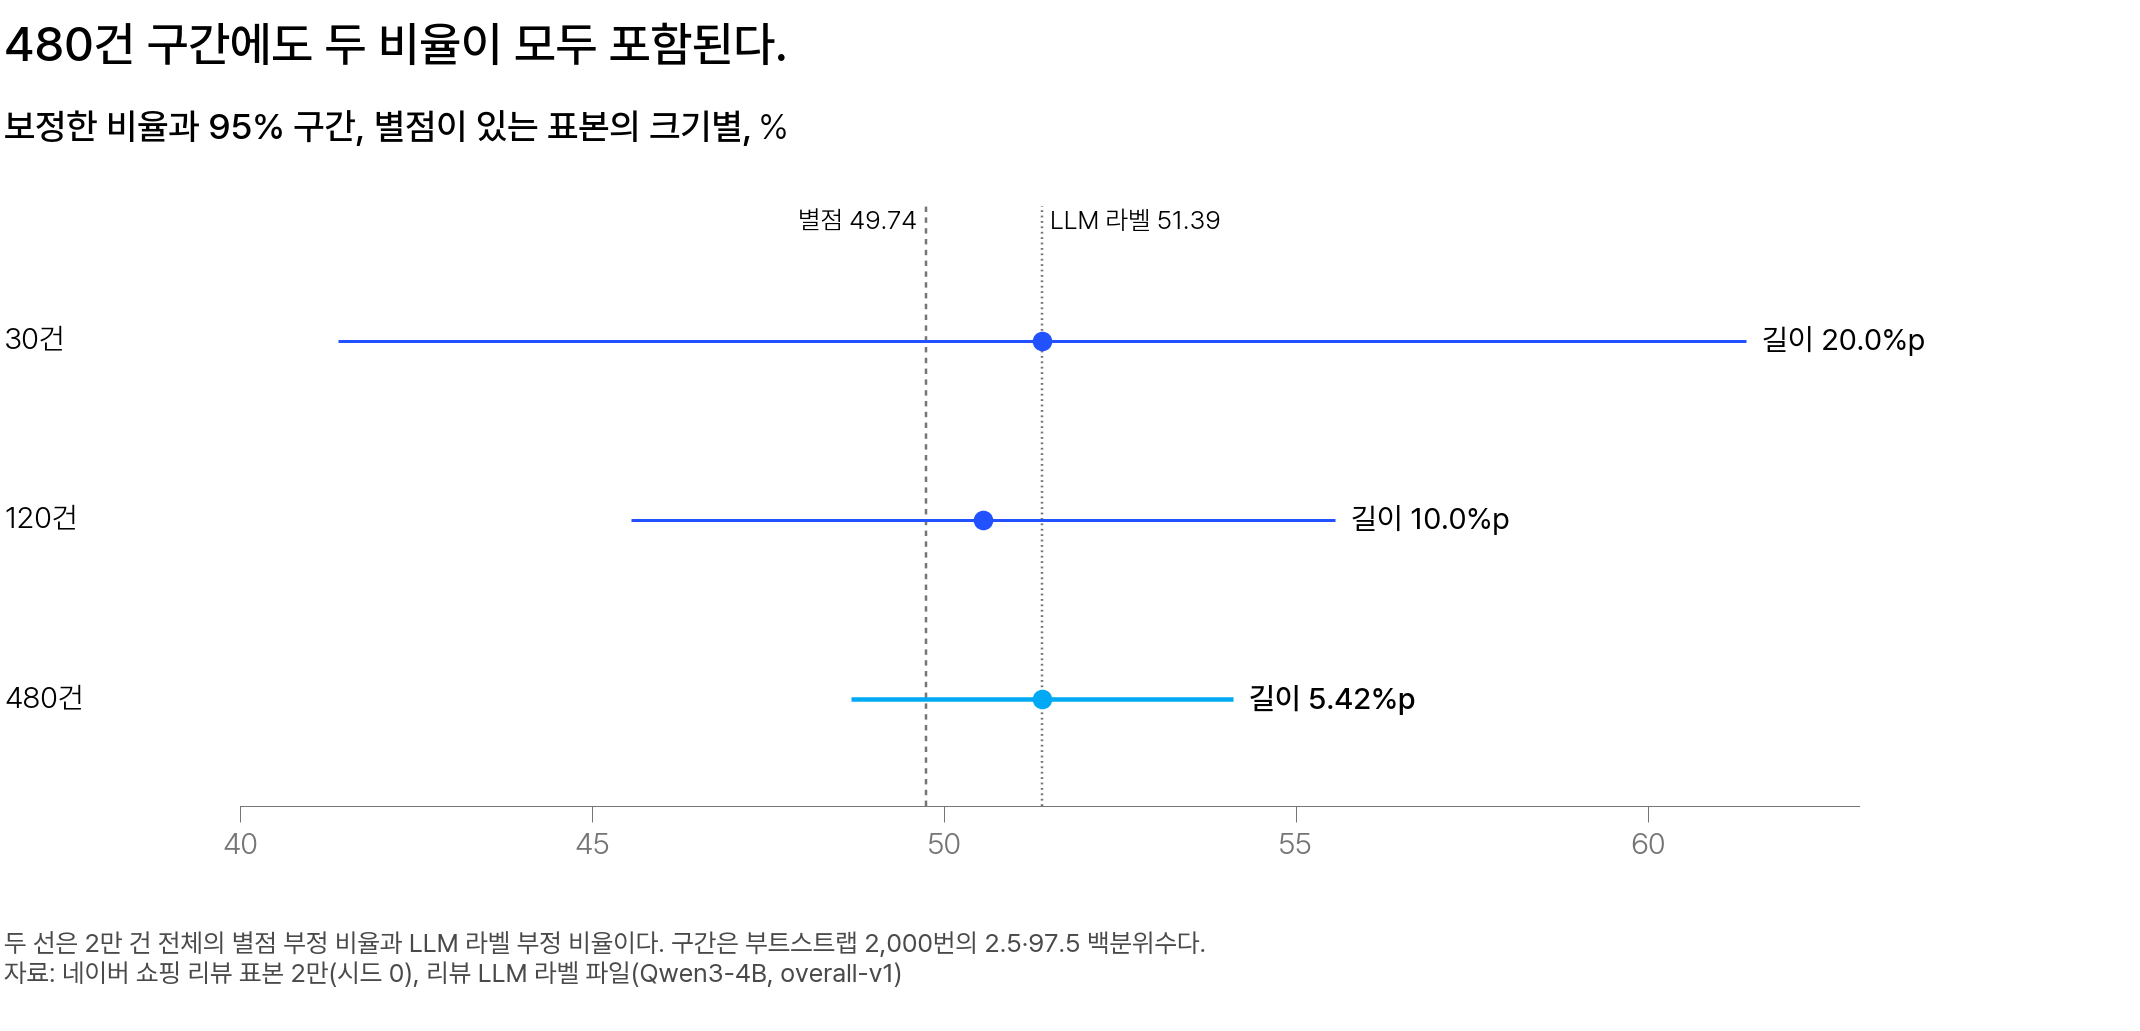

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 가로축은 부정 비율(%)이다. 가로 막대 하나가 표본 크기 하나(30 · 120 · 480건)로 구한 95% 구간이고, 점이 보정한 비율이다. 세로 점선 두 개는 2만 건의 별점 부정 비율과 LLM 라벨 부정 비율이다. 하늘색이 480건 구간이다</em></p>

- 구간 길이는 건수를 네 배로 늘릴 때마다 절반쯤이 됩니다. 표준오차 식의 첫 항은 LLM 라벨 비율이 어느 2만 건이냐에 따라 달라지는 정도입니다. 2만 건이나 되면 이 항은 거의 0 입니다. 그래서 전체가 500건이던 「3. 예측 기반 추론(PPI)」의 예와 달리 둘째 항 $s_d^2/n$ 만 남습니다.
- 30건과 480건은 두 방향의 건수가 같아서 보정한 비율이 LLM 라벨 비율과 같습니다.
- 세 구간 모두 별점과 LLM 라벨의 두 점선을 포함합니다.

**120건으로 2만 건의 편향을 알아낼 수 있나요?**

알아낼 수 없습니다. 120건 구간은 별점과 LLM 라벨의 두 비율을 모두 포함합니다.

```text
45.56 ── 49.74(별점) ── 50.56(보정한 비율) ── 51.39(LLM 라벨) ── 55.56
|<──────────────────── 120건의 95% 구간 ────────────────────>|
```

편향이 0 이면 참값 비율은 LLM 라벨 비율 51.39% 와 같습니다. 이 값이 120건 구간 안에 있으므로 편향이 0 이라는 가정을 버릴 근거가 없습니다. 480건으로 늘려도 두 비율이 모두 구간 안에 있습니다.

**별점으로 보정한 비율은 어떻게 쓰나요?**

참값이 표본에만 있으면 LLM 라벨 비율 대신 보정한 비율을 씁니다. 별점이 120건에만 있었다면 이렇게 씁니다.

> 리뷰 부정 비율 50.56%(95% 구간 45.56～55.56%). LLM 라벨 20,000건을 별점이 있는 표본 120건으로 보정한 비율. 모델 Qwen3-4B-Instruct-2507(버전 cdbee75f), 프롬프트 버전 overall-v1.

cdbee75f 는 모델 파일을 받은 저장소의 커밋 식별자입니다.

<details class="lms-extra"><summary>더 깊이 — 이 자료에서 본 PPI 가정</summary>

「3. 예측 기반 추론(PPI)」의 세 가정 가운데 둘째와 셋째 가정이 깨질 수 있다는 것을 이 자료에서 볼 수 있습니다.

- **둘째, 같은 모델 · 같은 프롬프트 버전.** 뜻이 같은 프롬프트 5개로 같은 리뷰 100건의 리뷰 전체 극성을 다시 라벨링했습니다. 부정 비율은 0.51～0.56 으로 달라져, 같은 100건의 별점 부정 비율 0.54 보다 낮게도 높게도 나왔습니다. 버전이 다르면 표본에서 구한 보정값을 전체에 더할 수 없습니다.
- **셋째, 참값에 오류가 없음.** 리뷰 번호 8761 의 별점 1점 리뷰 「배송빠르군요 잘쓸께요 굿」은 본문이 긍정입니다. 이 리뷰에서는 LLM 라벨 긍정이 오히려 본문과 맞습니다. 별점으로 보정한 비율은 고객이 느낀 극성보다 별점 부정 비율에 가깝습니다.

라벨 파일에는 리뷰마다 모델 이름 · 모델 버전 · 프롬프트 버전이 기록되어 있습니다. 골드 표본과 전체를 같은 버전으로 라벨링했는지는 이 기록으로 확인합니다.

</details>

<details class="lms-extra"><summary>더 깊이 — 식으로 계산한 120건의 구간</summary>

「3. 예측 기반 추론(PPI)」의 표준오차 식에 120건 값을 대입합니다.

$$
\text{SE} = \sqrt{\frac{\bar{\hat y}_N(1-\bar{\hat y}_N)}{N} + \frac{s_d^2}{n}}
$$

120건의 차이 $d_j$ 는 0 이 111건, +1 이 4건, −1 이 5건입니다. 평균은 $-1/120$ 입니다.

편차 제곱합은 $111 \times (1/120)^2 + 4 \times (121/120)^2 + 5 \times (119/120)^2 = 8.992$ 입니다. 이를 $n - 1 = 119$ 로 나누면 $s_d^2 = 0.07556$ 입니다.

| 계산 | 대입 | 값 |
|---|---|---:|
| 첫 항 | $0.5139 \times 0.4861 \div 20{,}000$ | 0.0000125 |
| 둘째 항 | $0.07556 \div 120$ | 0.0006297 |
| SE | $\sqrt{0.0000125 + 0.0006297}$ | 0.02534 |
| 95% 구간 | $50.557 \pm 1.96 \times 2.534$ | 45.59～55.52% |

이 구간은 부트스트랩 구간 45.56～55.56% 와 거의 같습니다. 첫 항은 둘째 항의 약 50분의 1 이라 구간 길이는 거의 둘째 항으로 정해집니다.

참값만 쓰면 둘째 항의 $s_d^2$ 대신 별점 값의 분산 $0.525 \times 0.475 = 0.249$ 를 씁니다. 차이가 0 인 리뷰가 111건이라 $s_d^2 = 0.0756$ 은 그 3분의 1 도 안 됩니다.

</details>

### 리뷰 길이 두 집단 [필수]

예시의 집단 A · B 처럼, 리뷰 2만 건에서도 LLM 라벨의 오차가 집단마다 같은지 확인합니다. 본문 길이의 중앙값 29자로 나눠 두 집단의 건수를 거의 같게 했습니다. 실제 극성은 별점 극성으로 정하고 재현율과 오탐률을 구했습니다.

| 집단 | 건수 | 재현율 | 오탐률 | 별점 부정 비율 | LLM 라벨 부정 비율 |
|---|---:|---:|---:|---:|---:|
| 짧은 리뷰(29자 이하) | 10,151 | 0.891 | 0.082 | 42.6% | 42.6% |
| 긴 리뷰(29자 초과) | 9,849 | 0.971 | 0.116 | 57.1% | 60.4% |
| 두 집단의 차이(긴 − 짧은) | | | | 14.5%p | 17.8%p |

두 집단의 재현율과 오탐률이 다릅니다. 긴 리뷰만 LLM 라벨 부정 비율이 별점보다 3.3%p 높아서, 두 집단의 차이도 3.3%p 커집니다. 차이의 방향은 같습니다.

이 3.3%p 가 어디서 생겼는지 보려고 예시와 같은 막대로 그렸습니다.

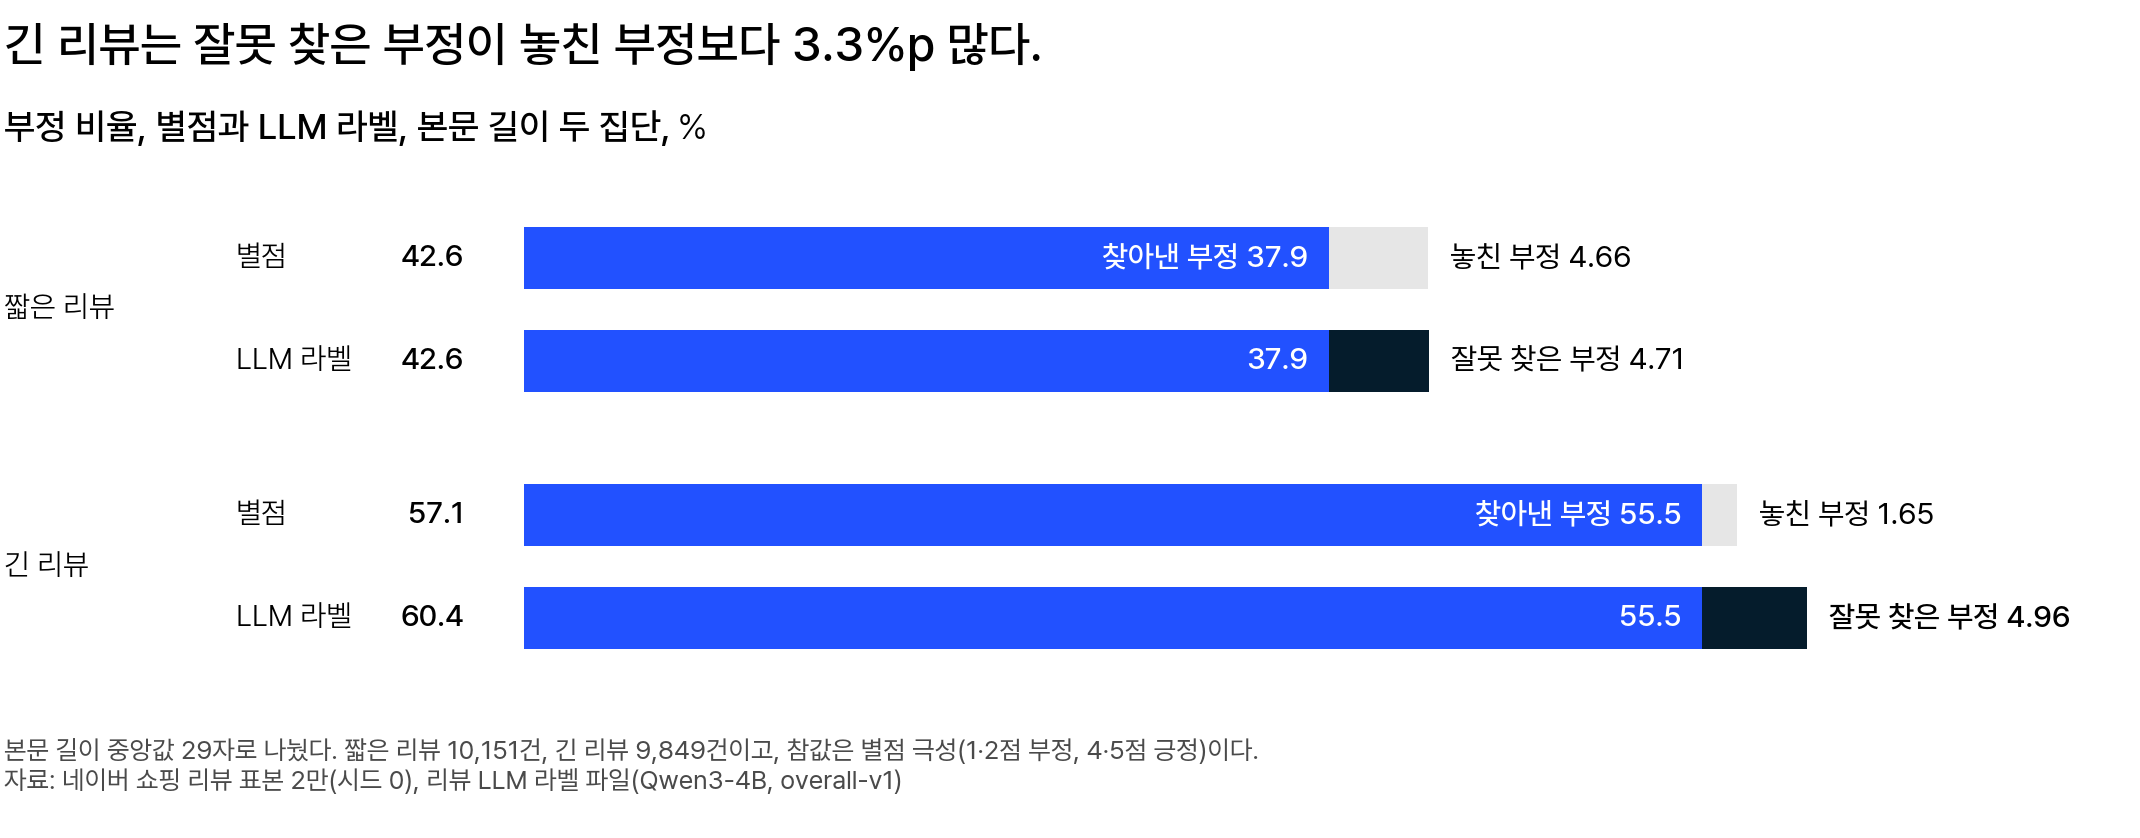

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 가로축은 부정 비율(%)이고 눈금 대신 막대마다 값이 있다. 집단마다 위 막대가 별점, 아래 막대가 LLM 라벨 부정 비율이다. 색은 예시 그림과 같아서 파랑은 찾아낸 부정, 회색은 놓친 부정, 남색은 잘못 찾은 부정이다</em></p>

**왜 긴 리뷰만 LLM 라벨 부정 비율이 높을까요?**

그림에서 짧은 리뷰는 회색과 남색 길이가 거의 같고, 긴 리뷰는 남색이 회색보다 깁니다. 건수로는 긴 리뷰의 잘못 찾은 부정이 놓친 부정보다 326건 많습니다.

| 집단 | 놓친 부정 | 잘못 찾은 부정 | 잘못 찾은 − 놓친 | 부정 비율 차이(LLM 라벨 − 별점) |
|---|---:|---:|---:|---:|
| 짧은 리뷰(10,151건) | 473건(4.66%) | 478건(4.71%) | 5건 | 5 ÷ 10,151 = +0.05%p |
| 긴 리뷰(9,849건) | 163건(1.65%) | 489건(4.96%) | 326건 | 326 ÷ 9,849 = +3.3%p |

두 집단의 놓친 부정을 더하면 636건, 잘못 찾은 부정을 더하면 967건입니다. 앞의 교차표에서 본 두 방향 건수와 같습니다. 긴 리뷰의 두 오차를 식의 두 항으로 나눠 보겠습니다.

- 놓친 부정 $p(1-r)$: 긴 리뷰는 재현율이 0.971 로 높아 적습니다.
- 잘못 찾은 부정 $(1-p) \times f$: 긴 리뷰는 오탐률이 높지만 실제 긍정이 적어, 짧은 리뷰와 비슷합니다.

> 긴 리뷰는 놓친 부정이 적어서, 잘못 찾은 부정이 상쇄되지 않고 LLM 라벨 부정 비율을 높였습니다.

예시의 집단 A · B 는 오탐률을 5% 로 같게 두었습니다. 실제 두 집단은 오탐률도 0.082 대 0.116 으로 달랐고, 짧은 리뷰에서는 두 오차가 상쇄됐습니다.

**3.3%p 는 모두 LLM 라벨의 잘못인가요?**

그렇게 말할 수 없습니다. 참값으로 쓴 별점도 본문과 다를 때가 있습니다. 두 라벨이 다른 리뷰 두 건입니다.

| 집단 | 리뷰 본문 | 별점 | LLM 라벨 | 별점을 참값으로 삼으면 |
|---|---|---|---|---|
| 짧은 리뷰 | 배송빠르군요 잘쓸께요 굿 | 1점 | 긍정 | 놓친 부정 |
| 긴 리뷰 | 가격대비 괜찮기는 합니다만 불빛이 약하네요. 좀더 강했으면 좋겠는데 많이 아쉬운 부분입니다. 또 사시죠 | 5점 | 부정 | 잘못 찾은 부정 |

- 첫째(리뷰 번호 8761)는 본문이 긍정이라 별점이 본문과 다릅니다.
- 둘째(리뷰 번호 181496)는 본문에 불만이 있어 LLM 라벨이 틀렸다고 단정할 수 없습니다.

별점은 고객이 직접 고른 값이고 2만 건 모두에 있습니다. 그래서 확인 전까지는 별점 차이 14.5%p 를 씁니다.

<details class="lms-extra"><summary>더 깊이 — 층화 추출(stratified sampling)</summary>

LLM 라벨의 잘못이 얼마인지는 두 집단에서 두 라벨이 다른 리뷰를 무작위로 골라 읽어 확인합니다. 읽을 건수는 「1. 골드 표본」의 오차 한계 식으로 정합니다. 집단마다 그 건수를 정해 따로 무작위로 고릅니다(층화 추출).

한 표본을 나중에 두 집단으로 나누면 건수가 모자랍니다. 별점이 120건에만 있다면 한 집단에 60건 안팎이고, 재현율의 분모인 실제 부정은 30건쯤입니다.

재현율이 0.9 쯤이면 한 집단의 오차 한계는 $1.96\sqrt{0.9 \times 0.1 \div 30} = 0.107$ 입니다. 두 집단은 겹치지 않는 리뷰라 두 재현율을 독립으로 보고, 차이의 오차 한계는 두 분산의 합으로 구합니다($\text{Var}(A-B) = \text{Var}(A) + \text{Var}(B)$).

$$
1.96\sqrt{0.9 \times 0.1 \div 30 + 0.9 \times 0.1 \div 30} = 0.152
$$

그래서 두 재현율 차이의 오차 한계 ±0.15 가 실제 재현율 차이 $0.971 - 0.891 = 0.08$ 보다 큽니다.

두 집단 모두 재현율이 0.9 쯤이고 실제 부정이 $n$ 건씩이면, 차이의 오차 한계는 $1.96\sqrt{0.18 \div n}$ 입니다. 이 값이 0.08 이하가 되려면 $n$ 이 약 108건 이상이어야 합니다. 그래서 「4. 집단마다 다른 라벨 오차」의 층화 추출로 집단마다 건수를 정해 고릅니다.

<img src="https://upload.wikimedia.org/wikipedia/commons/f/fa/Stratified_sampling.PNG" alt="번호 1부터 12까지의 사람 모양 12개가 흰색 3개, 짙은 색 6개, 옅은 색 3개로 나뉘어 있고, 색마다 따로 고른 10, 2와 8, 5 번이 화살표를 따라 표본 쪽으로 옮겨진 그림" width="460" height="400" />
<p align="center"><em>▲ 층화 추출. 모집단(Population)을 색으로 세 집단으로 나누고 집단마다 따로 무작위로 골라 표본(Sample)을 만든다. 흰색 3명에서 1명, 짙은 색 6명에서 2명, 옅은 색 3명에서 1명을 골랐다 (출처: Wikimedia Commons, Stratified sampling.PNG, Dan Kernler, CC BY-SA 4.0)</em></p>

</details>

**비율을 쓰기 전에 무엇을 확인하나요?**

별점과 비교한 편향, 보정한 비율, 두 집단 비교에서 확인한 내용을 아래 목록에 모았습니다.

1. 참값이 모든 건에 있으면 참값으로 비율을 구하고, 일부에만 있으면 PPI 로 보정했는가
2. 참값을 확인한 표본(골드 표본, 별점이 있는 표본)의 건수와 그 건수로 구한 95% 구간이 있는가
3. κ 만이 아니라 일치율과 라벨 비율도 계산했는가
4. 두 집단을 비교한다면, 집단마다 재현율과 오탐률이 같은가
5. 표본과 전체를 같은 모델, 같은 프롬프트 버전으로 라벨링했는가

5가지를 모두 확인해도 골드 표본이 작으면 구간이 넓습니다. 골드 표본 건수는 필요한 구간 길이와 라벨에 드는 시간으로 정합니다.

<details class="lms-extra"><summary>자세히 — 그림 읽기: 건수와 최대 오차 한계</summary>

<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/6/63/Margin_of_error_vs_sample_size_and_confidence_level.svg/960px-Margin_of_error_vs_sample_size_and_confidence_level.svg.png" alt="가로축 표본 크기 n 10 부터 10만, 세로축 오차 한계 0.1 부터 100 퍼센트인 로그 스케일 그래프. 신뢰 수준마다 오른쪽 아래로 내려가는 평행한 직선이 있고, 검은 점선이 95% 이다. n = 1000 에서 95% 는 3.1, 99% 는 4.1 이라고 화살표로 표시되어 있고, 오른쪽 위 작은 그림은 p 에 따른 보정 계수 곡선이다" width="560" height="420"/>
<p align="center"><em>▲ 가로축은 표본 크기 n, 세로축은 비율의 최대 오차 한계(±%)이고 가로축과 세로축 모두 로그 스케일이다. 직선 하나가 신뢰 수준 하나이고 검은 점선이 95% 구간이다 (출처: Wikimedia Commons, Margin of error vs sample size and confidence level.svg, Cmglee, CC BY-SA 4.0)</em></p>

검은 점선은 「1. 골드 표본」의 식 $1.96\sqrt{0.25 \div n}$ 을 그린 선이고 30건에서 ±17.9%p 를 지납니다.

</details>

<div class="lms-summary">

**정리**

- 리뷰 전체 부정 비율은 2만 건 모두에 있는 별점으로 구한 49.74% 를 씁니다. LLM 라벨은 κ 0.84 여도 별점보다 높게 편향되어 있습니다.
- 속성별 부정 비율은 LLM 라벨 1,000건의 비율(품질 35.8% 등)을 그대로 쓰지 않고 골드 표본으로 보정한 비율을 씁니다. 그 비율을 얼마나 믿을지는 95% 구간과 골드 표본 건수로 판단합니다.
- 리뷰 길이 두 집단은 재현율이 달라 LLM 라벨로 본 차이가 3.3%p 커졌습니다. 두 집단의 부정 비율은 집단마다 재현율과 오탐률을 확인한 뒤 비교합니다.

**할 일**

- 골드 표본은 무작위로 고르고, 건수는 필요한 구간 길이와 라벨 시간으로 정합니다.
- 보정한 비율은 표본과 버전이 바뀌면 달라지므로 구간 · 표본 건수 · 모델과 프롬프트 버전을 기록합니다.

속성 라벨이 맞는지는 κ 가 아니라 골드 표본으로 판단합니다.

</div>

> **[문제] 리뷰 2만 건의 LLM 라벨 부정 비율은 51.39% 입니다. 별점이 있는 표본 120건에서 별점 부정 비율은 52.50%, LLM 라벨 부정 비율은 53.33% 입니다. 보정한 비율은 얼마일까요?**
>
> 1. 51.39%
> 2. 50.56%
> 3. 52.50%
> 4. 49.74%

### 팀 라운드: 골드 표본을 몇 건 만들 것인가 [필수]

아래 질문의 답은 수업에서 팀이 함께 정합니다. 지금은 자기 답과 근거만 적어 두면 됩니다.

각자 답과 확신도(1～5)를 적어 잠그면 팀의 답 분포가 공개됩니다. 근거 세 문장을 나눠 토론한 뒤 팀이 답 하나로 모아 제출합니다.

> **[문제] 팀 라운드: 골드 표본을 몇 건 만들 것인가**
>
> 분석팀은 이번 달 리뷰의 속성별 부정 비율을 다음 달 초 운영팀에 보내기 전에, 골드 표본을 몇 건으로 할지 정해야 합니다. 이 비율은 LLM 라벨 부정 비율이고, 지금 골드 표본은 30건입니다. 30건을 라벨링하는 데 t 분이 걸렸고, 시간은 건수에 비례합니다.
> 
> - **속성별 부정 비율(LLM 라벨, 1,000건)** 품질 35.8%, 사이즈 9.2%, 배송 7.5%
> - **리뷰 전체 극성 2만 건(LLM 라벨과 별점 극성)** κ 0.84, 부정 비율은 LLM 라벨이 1.65%p 높음
> - **골드 표본 건수별 라벨 시간과 일치율의 최대 오차 한계** 30건 t 분 ±17.9%p, 120건 4t 분 ±8.9%p, 480건 16t 분 ±4.5%p
> - **별점 연습에서 보정한 비율의 95% 구간 길이** 30건 20.0%p, 120건 10.0%p, 480건 5.42%p
> 
> 팀 안에서 의견이 3가지로 나뉘었습니다.
> 
> - **관점 A: 골드 표본을 120건으로 늘려, 품질 부정 비율만 보정하고 그 구간을 좁힌다.** 건수를 네 배로 늘리면 보정한 비율의 구간이 절반쯤이 되니, 가장 큰 품질 비율만큼은 범위를 좁힌 뒤 보낸다. 배송과 사이즈는 이번 달에는 뺀다.
> - **관점 B: κ 0.84 를 믿고, 골드 표본은 30건으로 둔 채 세 비율을 모두 낸다.** κ 는 2만 건에서 구한 「거의 완전한 일치」라 골드 표본 30건보다 근거가 크다. 30건으로도 전체 일치율의 범위를 구해, 라벨이 크게 틀리지 않았음은 확인했다.
> - **관점 C: 지금은 30건으로 보정한 품질 부정 비율만 「대략」의 값이라고 전하고, 배송 대 사이즈 비교는 뺀다.** 30건으로도 보정한 비율과 구간은 구할 수 있고 시간이 더 들지 않는다. 배송과 사이즈의 차이는 480건으로 보정한 구간 길이보다도 작으니, 비교는 빼고 골드 표본은 다음 달까지 더 모은다.
> 
> 자기 입장 하나와 근거 세 문장, 다음에 확인할 일 하나, 그리고 확신도를 정해 오세요.